<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lesson 03 · Applied AI: unstructured data</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">01 · Text Mining basics: SMS spam</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">How does text become numbers?</p>
</div>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/03-applied-ai-projects/blob/main/01_text_mining/01_mini_project_sms_spam/01_Text_Mining_Basics_SMS_Spam.ipynb) [![Slides](https://img.shields.io/badge/slides-Text_mining-ffd43b)](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#text-mining)

## 🎯 Objectives
This notebook is the **hands-on tour of the Text mining slides**: every idea from the theory, in the same order, first on tiny toy examples you can check by eye, then on 5,574 real SMS messages. By the end you will be able to:

- cut a text into **tokens** (split, cleaning, stop words) and explain why modern models use **sub-words** (BPE, WordPiece);
- score a text with a **sentiment lexicon** (AFINN, VADER) and say where hand-written dictionaries break;
- build a **vocabulary**, a **bag of words** and a **TF-IDF** table by hand and check them against scikit-learn;
- compare texts with **cosine similarity**, and see what **word vectors** add (similar words, analogies) and what they still miss;
- train and judge a real **spam filter**: the accuracy trap, precision / recall / F1, and the cost of losing your boss's message;
- take a first look at **context**: the same word getting a different vector in each sentence.

**⏱️ Duration:** ≈ 90 min · **📋 Prerequisites:** Lesson 02 (train/test split, `Pipeline`, precision/recall/F1, confusion matrix) and the Text mining slides · **▶️ How to use:** run the cells in order with `Shift`+`Enter`; try the ✏️ exercises before opening the solutions. Each section starts with a 🎞️ link to the slides it practises.

## 📑 Contents

1. [🧩 Why text is hard](#sec-1)
2. [✂️ Tokens: cutting text into pieces](#sec-2)
3. [🧱 Words, characters or sub-words?](#sec-3)
4. [📖 Idea 1: a dictionary of word scores (lexicons)](#sec-4)
5. [🎒 Idea 2: the bag of words](#sec-5)
6. [⚖️ Idea 3: TF-IDF](#sec-6)
7. [📐 Comparing texts: cosine similarity, and the limit of counting](#sec-7)
8. [🧭 Idea 4: word vectors](#sec-8)
9. [📱 The SMS spam problem](#sec-9)
10. [📏 Which metric? The accuracy trap](#sec-10)
11. [🤖 Two spam filters: Naive Bayes and Logistic Regression](#sec-11)
12. [👔 The boss email: which mistake costs more?](#sec-12)
13. [🔍 What did the model learn, and where does it fail?](#sec-13)
14. [🔮 A first look at context](#sec-14)
15. [✍️ Try your own messages](#sec-15)
16. [📌 Summary](#sec-16)
17. [📚 Learn more](#sec-17)

<a id="sec-0"></a>
## ⚙️ Setup

In [1]:
# ⚙️ Setup: works locally (VS Code / Jupyter) and in Google Colab
import os
import subprocess
import sys
import warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/03-applied-ai-projects")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/03-applied-ai-projects.git", str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "vaderSentiment", "sentence-transformers"], check=True)
else:  # locally: walk up until we find the folder that has src/ and data/
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())

sys.path.insert(0, str(ROOT))

# Quieter output: no download bars or library chatter
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
warnings.filterwarnings("ignore")
print("Project root:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Project root: 03-applied-ai-projects (local)


In [2]:
import re
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

from src.paths import data_dir
from src.plotting import CLASS_COLORS, PALETTE, apply_style, label_bars, plot_confusion
from src.text import clean_tweet, lexicon_score, load_lexicon, tokenize, top_coefficients

apply_style()
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)
T_START = time.perf_counter()  # to report the total run time at the end

DATA = data_dir("sms_spam", "lexicons")  # downloads the two datasets the first time (≈ 1 MB)
print("Ready. No GPU needed: everything runs on a laptop CPU (one small model of ≈ 90 MB is downloaded in section 3).")

Ready. No GPU needed: everything runs on a laptop CPU (one small model of ≈ 90 MB is downloaded in section 3).


<a id="sec-1"></a>
# 1. 🧩 Why text is hard

> 🎞️ **Slides:** [Text mining: what is it?](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm1-what) · [Models eat tables of numbers](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm1-hard)

**Text mining** = getting answers out of text automatically: is this SMS spam? is this review happy? what is this article about? which document matches my search?

Every model you trained in Lesson 02 received **X**: one row per example, the same numeric columns for every row. Text breaks all of that. Let's see it on the real data we will use all along: the **SMS Spam Collection**, 5,574 real English text messages, each tagged `ham` (a normal message) or `spam`.

In [3]:
sms = pd.read_csv(DATA / "sms_spam" / "sms_spam.csv")
print(sms.shape)
sms.sample(6, random_state=3)

(5574, 2)


,label,text
2155,ham,Oh god i am happy to see your message after 3 days
4072,ham,I've reached home n i bathe liao... U can call me now...
615,ham,I called and said all to him:)then he have to choose this future.
3816,ham,"Not yet chikku..k, then wat abt tht guy did he stopped irritating or msging to u.."
1927,ham,"Dont give a monkeys wot they think and i certainly don't mind. Any friend of mine&all that! Just don't sleep wiv , t..."
2391,ham,First has she gained more than &lt;#&gt; kg since she took in. Second has she done the blood sugar tests. If she ha...


Four reasons why this is not a table yet (the four red boxes of the slide), checked on the data:

In [4]:
lengths = sms["text"].str.split().str.len()
print(f"1 · LENGTH   from {lengths.min()} to {lengths.max()} words per message: how many columns would that be?")

word_counts = Counter(w for t in sms["text"] for w in re.findall(r"[a-z0-9']+", t.lower()))
print("2 · SPELLING one meaning, many forms:")
for forms in [["you", "u", "ya"], ["tomorrow", "tmr", "tomo", "2mrw", "2moro", "2morrow"], ["please", "pls", "plz"]]:
    print("            ", " · ".join(f"{w} ×{word_counts[w]}" for w in forms))

free_ham = sms.loc[(sms["label"] == "ham") & sms["text"].str.contains("are you free", case=False), "text"].iloc[0]
free_spam = sms.loc[(sms["label"] == "spam") & sms["text"].str.contains(r"\bfree\b", case=False), "text"].iloc[1]
print(f"3 · MEANING  'free' = available: {free_ham!r}")
print(f"             'free' = no cost:   {free_spam[:70]!r}…")
print("4 · ORDER     'not good' vs 'good': same words, opposite meaning (we come back to this in section 5)")

1 · LENGTH   from 1 to 171 words per message: how many columns would that be?
2 · SPELLING one meaning, many forms:
             you ×2156 · u ×1188 · ya ×58
             tomorrow ×93 · tmr ×28 · tomo ×19 · 2mrw ×5 · 2moro ×4 · 2morrow ×3
             please ×135 · pls ×134 · plz ×25
3 · MEANING  'free' = available: 'Are you free now?can i call now?'
             'free' = no cost:   'Had your mobile 11 months or more? U R entitled to Update to the lates'…
4 · ORDER     'not good' vs 'good': same words, opposite meaning (we come back to this in section 5)


> 🧠 **How it works (the big idea of the whole section)**
> 1. **Cut** each text into pieces we can count and look up: **tokens**.
> 2. **Turn** the tokens into numbers: a score per word (lexicon), counts (bag of words), weights (TF-IDF) or learned vectors (word vectors).
> 3. Now every text is **a row of numbers**, and everything from Lesson 02 works again: split, `Pipeline`, metrics, threshold.

> 📖 **Mini-glossary**
> - **Corpus**: the collection of texts we work with. **Document**: one text of the corpus (a sentence, an SMS, a review).
> - **Token**: one piece of text treated as a unit (a word, a piece of a word, a character, a symbol like `!`).
> - **Vocabulary**: the list of different tokens; each one gets a fixed number (its **token id**, or its column).

<a id="sec-2"></a>
# 2. ✂️ Tokens: cutting text into pieces

> 🎞️ **Slides:** [A token is the unit a model reads](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm1-token) · [Cut at every space](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm1-split) · [Clean first](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm1-clean) · [Stop words](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm1-stop)

A **tokenizer** is the rule that cuts text into tokens. The model never sees letters: each token is replaced by its **token id**, a number like a word's position in a dictionary. A toy version:

In [5]:
sentence = "I love this phone!"
pieces = ["I", "love", "this", "phone", "!"]          # cut by hand, for now
toy_ids = {"I": 14, "love": 302, "this": 27, "phone": 1190, "!": 3}   # toy numbers, as on the slide
print(pieces, "→", [toy_ids[p] for p in pieces])

['I', 'love', 'this', 'phone', '!'] → [14, 302, 27, 1190, 3]


### The simplest tokenizer: cut at every space
Plain Python, no library: `text.split()` cuts wherever there is a space.

In [6]:
text = "I love this phone, it's GREAT!! 😍"
split_tokens = text.split()
print(len(split_tokens), "tokens:", split_tokens)
print("'phone,' == 'phone'?", "phone," == "phone", "· 'GREAT!!' == 'great'?", "GREAT!!" == "great")

7 tokens: ['I', 'love', 'this', 'phone,', "it's", 'GREAT!!', '😍']
'phone,' == 'phone'? False · 'GREAT!!' == 'great'? False


It works, but `phone,` and `phone` are now two different "words", and so are `GREAT!!` and `great`. When we count words later, the evidence for one word gets split across its variants.

### Clean first: lower case, then keep only letters
Two steps: `lower()` merges *GREAT*, *Great* and *great*; then a **regular expression** (a search pattern) keeps only runs of letters, digits and `'`. Everything else becomes a cut point and disappears.

In [7]:
def clean_tokens(text):
    """Lower case, then keep runs of letters, digits and apostrophes (everything else is a cut)."""
    return re.findall(r"[a-z0-9']+", text.lower())

print(clean_tokens("I love this phone, it's GREAT!! 😍"))
print(clean_tokens("Adoro pastéis de nata :)"))    # [a-z] has no é, and the smiley is gone

['i', 'love', 'this', 'phone', "it's", 'great']
['adoro', 'past', 'is', 'de', 'nata']


The second line shows that cleaning is a **choice**, not a law: *pastéis* breaks in two (no `é` in `[a-z]`) and the smiley `:)` is lost. For sentiment, `!!`, `:)` and 😍 were strong clues. For spam, the `£` sign and long phone numbers are clues too.

### Stop words: very common words that say little
*the, a, is, to, of…* appear in almost every text, so they tell us little about what a text is about. scikit-learn ships a ready-made English list.

In [8]:
print(len(ENGLISH_STOP_WORDS), "stop words in scikit-learn's list, e.g.", sorted(ENGLISH_STOP_WORDS)[:12])

def drop_stop_words(tokens):
    return [t for t in tokens if t not in ENGLISH_STOP_WORDS]

for text in ["I love this phone, the battery is great", "this movie is not good"]:
    print(f"{text!r:45} → {drop_stop_words(clean_tokens(text))}")

318 stop words in scikit-learn's list, e.g. ['a', 'about', 'above', 'across', 'after', 'afterwards', 'again', 'against', 'all', 'almost', 'alone', 'along']
'I love this phone, the battery is great'     → ['love', 'phone', 'battery', 'great']
'this movie is not good'                      → ['movie', 'good']


⚠️ The list contains **not**, **no** and **never**: *"this movie is not good"* becomes `['movie', 'good']`, a positive text! For topics or spam, dropping stop words is usually harmless; for opinions, keep the negations.

### ✏️ Exercise 1 — Tokenise a real spam (Difficulty ⭐)
Take the spam message `sms.loc[418, "text"]`. Tokenise it with `.split()`, with `clean_tokens` and with `clean_tokens` + `drop_stop_words`. How many tokens does each version give? Which **spam clues** disappear on the way?

In [9]:
# TODO: three tokenisations of the same spam message
spam_example = sms.loc[418, "text"]

<details>
<summary>💡 Show solution</summary>

```python
spam_example = sms.loc[418, "text"]
print(spam_example)
for name, toks in [("split", spam_example.split()),
                   ("clean", clean_tokens(spam_example)),
                   ("clean + no stop words", drop_stop_words(clean_tokens(spam_example)))]:
    print(f"{name:22} {len(toks):2d} tokens: {toks}")
```
Cleaning drops the **capitals** (*FREE*, *WIN*, *NOW*), the **£** sign and the punctuation, and cuts the web address into pieces (*www*, *txttowin*, *co*, *uk*); stop-word removal also drops words like *into*, *our*, *just*, *the*. The numbers (*250*, *80086*, *18*) survive because the pattern keeps digits. Each of those lost clues could help a spam filter: tokenising is a design decision for the task.
</details>

<a id="sec-3"></a>
# 3. 🧱 Words, characters or sub-words?

> 🎞️ **Slides:** [How small is a token?](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm1-levels) · [Byte-Pair Encoding](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm1-bpeidea) · [BPE step by step](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm1-bpe) · [Modern models read sub-words](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm1-sub) · [Why tokens matter today](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm1-today)

Three ways to cut the same text:

In [10]:
text = "unbelievably slow!"
levels = {
    "words": re.findall(r"\w+|[^\w\s]", text),
    "characters": list(text.replace(" ", "␣")),
}
for name, toks in levels.items():
    print(f"{name:11} {len(toks):2d} tokens: {toks}")

words        3 tokens: ['unbelievably', 'slow', '!']
characters  18 tokens: ['u', 'n', 'b', 'e', 'l', 'i', 'e', 'v', 'a', 'b', 'l', 'y', '␣', 's', 'l', 'o', 'w', '!']


- **Words**: few tokens, but a **huge** vocabulary (*play, plays, played, playing…* are all different) and every new word or typo is **unknown**.
- **Characters**: a tiny vocabulary (about a hundred symbols) and nothing is ever unknown, but sequences become very long and each piece means little.
- **Sub-words**: the sweet spot. Common words stay whole, rare words are built from smaller known pieces, like LEGO. That is what modern language models use.

### Where do the sub-words come from? BPE by hand
> 🧠 **How it works: Byte-Pair Encoding (BPE)**
> 1. Start with single letters.
> 2. Count every pair of neighbouring pieces in a training text (weighted by how often each word appears).
> 3. **Merge** the most frequent pair into one new token.
> 4. Repeat until the vocabulary is big enough (GPT-2 did 50,000 merges).
>
> **Analogy:** keep gluing together the two LEGO bricks you see side by side most often.

We run it on the slide's tiny training text: *low* ×5, *lower* ×2, *newest* ×6, *widest* ×3.

In [11]:
def count_pairs(words):
    """Count neighbouring pairs inside every word, weighted by how often the word appears."""
    pairs = Counter()
    for pieces, freq in words.items():
        for a, b in zip(pieces, pieces[1:]):
            pairs[(a, b)] += freq
    return pairs


def apply_merge(pieces, pair):
    """Glue every occurrence of `pair` inside one word (a tuple of pieces)."""
    out, i = [], 0
    while i < len(pieces):
        if i + 1 < len(pieces) and (pieces[i], pieces[i + 1]) == pair:
            out.append(pieces[i] + pieces[i + 1])
            i += 2
        else:
            out.append(pieces[i])
            i += 1
    return tuple(out)


training = {"low": 5, "lower": 2, "newest": 6, "widest": 3}
words = {tuple(w): n for w, n in training.items()}             # step 1: single letters
bpe_vocab = list(dict.fromkeys(c for w in training for c in w))
merges = []
print(f"start: {len(bpe_vocab)} tokens {bpe_vocab}")
for step in range(1, 5):
    best, n = count_pairs(words).most_common(1)[0]            # step 2 (ties: the pair seen first wins)
    words = {apply_merge(p, best): f for p, f in words.items()}  # step 3
    merges.append(best)
    bpe_vocab.append("".join(best))
    print(f"merge {step}: {best[0]} + {best[1]} ({n}×) → '{''.join(best)}'   words now: {[' '.join(p) for p in words]}")

start: 10 tokens ['l', 'o', 'w', 'e', 'r', 'n', 's', 't', 'i', 'd']
merge 1: e + s (9×) → 'es'   words now: ['l o w', 'l o w e r', 'n e w es t', 'w i d es t']
merge 2: es + t (9×) → 'est'   words now: ['l o w', 'l o w e r', 'n e w est', 'w i d est']
merge 3: l + o (7×) → 'lo'   words now: ['lo w', 'lo w e r', 'n e w est', 'w i d est']
merge 4: lo + w (7×) → 'low'   words now: ['low', 'low e r', 'n e w est', 'w i d est']


Each merge adds exactly one token. Now the magic: **"lowest" never appeared in the training text**, yet we can encode it by applying the same merges in order.

In [12]:
def bpe_encode(word, merges):
    pieces = tuple(word)
    for pair in merges:
        pieces = apply_merge(pieces, pair)
    return list(pieces)

for w in ["lowest", "newer", "slow"]:
    print(f"{w:7} → {bpe_encode(w, merges)}")

lowest  → ['low', 'est']
newer   → ['n', 'e', 'w', 'e', 'r']
slow    → ['s', 'low']


*lowest* = `low` + `est`: two known pieces, nothing lost. Real tokenizers run tens of thousands of merges on gigabytes of text.

### A real sub-word tokenizer
We load a small pretrained model, **MiniLM** (`all-MiniLM-L6-v2`, ≈ 90 MB, downloaded once and reused in sections 8 and 14). Its tokenizer is **WordPiece**, the same 30,522-piece vocabulary as BERT. `##` means "glued to the previous piece".

In [13]:
from sentence_transformers import SentenceTransformer

t0 = time.perf_counter()
minilm = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")  # ≈ 90 MB the first time
wordpiece = minilm.tokenizer
print(f"Loaded in {time.perf_counter() - t0:.0f} s · vocabulary: {wordpiece.vocab_size:,} pieces")

for text in ["unbelievably slow!", "gooooal", "I love this phone, it's GREAT!! 😍", "You are a w1nner! Cl4im your FR33 pr1ze"]:
    pieces = wordpiece.tokenize(text)
    print(f"{text!r:42} → {pieces}")
print("token ids of 'I love this phone!':", wordpiece("I love this phone!")["input_ids"])

Loaded in 1 s · vocabulary: 30,522 pieces
'unbelievably slow!'                       → ['un', '##bel', '##ie', '##va', '##bly', 'slow', '!']
'gooooal'                                  → ['goo', '##oo', '##al']
"I love this phone, it's GREAT!! 😍"        → ['i', 'love', 'this', 'phone', ',', 'it', "'", 's', 'great', '!', '!', '[UNK]']
'You are a w1nner! Cl4im your FR33 pr1ze'  → ['you', 'are', 'a', 'w', '##1', '##nne', '##r', '!', 'cl', '##4', '##im', 'your', 'fr', '##33', 'pr', '##1', '##ze']
token ids of 'I love this phone!': [101, 1045, 2293, 2023, 3042, 999, 102]


Notice: no word is lost (*gooooal* = `goo` + `##oo` + `##al`), capitals are merged (this model is *uncased*), and the emoji becomes `[UNK]` (unknown) because this vocabulary has no emoji. The real ids also include two special tokens at the start and end (`101` = `[CLS]`, `102` = `[SEP]`).

### Why tokens matter today
Chatbots read, remember and **charge** by tokens. Rule of thumb for English: 1 token ≈ 4 characters ≈ ¾ of a word. Other languages often need more tokens for the same content.

In [14]:
pairs = {"English": "The weather is lovely today and I want to go to the beach.",
         "Portuguese": "O tempo está ótimo hoje e eu quero ir à praia."}
rows = []
for language, text in pairs.items():
    rows.append({"language": language, "words": len(text.split()), "characters": len(text),
                 "chars / 4 (rule of thumb)": round(len(text) / 4), "WordPiece tokens": len(wordpiece.tokenize(text))})
display(pd.DataFrame(rows))
print("Portuguese pieces:", wordpiece.tokenize(pairs["Portuguese"]))
print("'strawberry' →", wordpiece.tokenize("strawberry"), "· the model gets one id, not ten letters: counting the r's is hard!")

,language,words,characters,chars / 4 (rule of thumb),WordPiece tokens
0,English,13,58,14,14
1,Portuguese,11,46,12,17


Portuguese pieces: ['o', 'tempo', 'est', '##a', 'ot', '##imo', 'ho', '##je', 'e', 'eu', 'que', '##ro', 'ir', 'a', 'pr', '##aia', '.']
'strawberry' → ['strawberry'] · the model gets one id, not ten letters: counting the r's is hard!


This English-trained vocabulary cuts the Portuguese sentence into many more pieces (*hoje* → `ho` + `##je`): more tokens means more cost, slower answers and less room in the context window.

### ✏️ Exercise 2 — Your own words (Difficulty ⭐)
Tokenise your name, a word of slang (*"slaps"*, *"yeet"*), a typo (*"definately"*) and an SMS-style message (*"c u 2morrow m8"*) with `wordpiece.tokenize(...)` and with `bpe_encode(..., merges)`. Which ones stay whole?

In [15]:
# TODO: tokenise your own words with both tokenizers

<details>
<summary>💡 Show solution</summary>

```python
for w in ["maria", "slaps", "yeet", "definately", "c u 2morrow m8"]:
    print(f"{w:16} WordPiece: {wordpiece.tokenize(w)}")
print("BPE toy:", bpe_encode("lowest", merges), bpe_encode("wider", merges))
```
Common English words are single pieces; names, slang, typos and SMS shorthand are split into several pieces, but **never lost**. Our toy BPE only knows 4 merges, so most words stay as single letters: real vocabularies need tens of thousands of merges.
</details>

<a id="sec-4"></a>
# 4. 📖 Idea 1: a dictionary of word scores (lexicons)

> 🎞️ **Slides:** [A dictionary of word scores](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-lex) · [AFINN vs VADER](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-lexdemo) · [Where a dictionary breaks](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-lexlim)

We have tokens; how do we get numbers? The oldest answer needs **no machine learning**: a person writes a dictionary (a **lexicon**) that gives each word a feeling score.

> 🧠 **How it works: lexicon scoring**
> 1. Cut the text into tokens. 2. Look up each token in the dictionary (unknown words count 0). 3. Add the scores.
>
> - **AFINN**: 3,382 English words, scores from −5 to +5. **VADER**: about 7,500 entries made for social media, plus rules for *not*, *very*, CAPITALS and `!`.
> - **Limits:** someone has to write and maintain every word and every rule, for every task.

In [16]:
afinn = load_lexicon(DATA / "lexicons" / "afinn_lexicon.txt")
print(f"AFINN: {len(afinn):,} words, e.g.", {w: afinn[w] for w in ["superb", "love", "delicious", "friendly", "sorry", "rude", "terrible"]})

total, table = lexicon_score(tokenize(clean_tweet("the pizza was delicious, the staff friendly")), afinn,
                             negation=False, explain=True)
display(table[["token", "lexicon"]].T)
print("score =", total, "→ positive 🙂" if total > 0 else "→ negative 🙁")

AFINN: 3,382 words, e.g. {'superb': 5.0, 'love': 3.0, 'delicious': 3.0, 'friendly': 2.0, 'sorry': -1.0, 'rude': -2.0, 'terrible': -3.0}


,0,1,2,3,4,5,6,7
token,the,pizza,was,delicious,",",the,staff,friendly
lexicon,0.0,0.0,0.0,3.0,0.0,0.0,0.0,2.0


score = 5.0 → positive 🙂


Now the same sentences with three scorers: the plain AFINN sum, AFINN with a simple **negation rule** (from `src/text.py`: after *not*, *never*, *n't*… flip the sign of the next words until a punctuation mark) and **VADER** (word scores + hand-written rules, squeezed into a "compound" score between −1 and +1).

In [17]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()

def three_scores(text):
    toks = tokenize(clean_tweet(text))
    return {"text": text,
            "AFINN (sum)": lexicon_score(toks, afinn, negation=False),
            "AFINN + negation rule": lexicon_score(toks, afinn, negation=True),
            "VADER compound": round(vader.polarity_scores(text)["compound"], 2)}

examples = ["not bad", "not good", "VERY good!!!", "I love the screen but the battery is awful",
            "the bus arrives at nine", "the food is very very good", "great, my flight is delayed again",
            "this song is fire, it slaps"]
pd.DataFrame([three_scores(t) for t in examples]).set_index("text")

,AFINN (sum),AFINN + negation rule,VADER compound
text,,,
not bad,-3.0,3.0,0.43
not good,3.0,-3.0,-0.34
VERY good!!!,3.0,3.0,0.70
I love the screen but the battery is awful,0.0,0.0,-0.34
the bus arrives at nine,0.0,0.0,0.00
the food is very very good,3.0,3.0,0.54
"great, my flight is delayed again",2.0,2.0,0.49
"this song is fire, it slaps",-2.0,-2.0,-0.34


Read the table like the slide's five cases:
1. **Negation:** the plain sum says *"not bad"* = −3. A rule fixes it, but a person had to write that rule.
2. **Intensity:** *"very very good"* = *"good"* for AFINN; VADER has a rule for *very*, CAPITALS and `!!!`.
3. **Sarcasm:** *"great, my flight is delayed again"* comes out positive for both.
4. **Slang:** *"fire"* is negative in the dictionary, *"slaps"* is not in it at all.
5. **Other tasks:** a sentiment dictionary only answers "how positive?". Watch what it says about spam:

,mean,share_positive
label,,
ham,0.81,0.37
spam,2.14,0.67


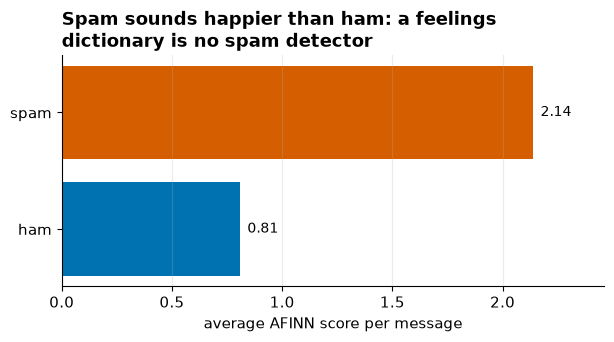

In [18]:
sms["afinn"] = [lexicon_score(tokenize(clean_tweet(t)), afinn, negation=False) for t in sms["text"]]
summary = sms.groupby("label")["afinn"].agg(mean="mean", share_positive=lambda s: (s > 0).mean()).round(2)
display(summary)

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(summary.index, summary["mean"], color=[CLASS_COLORS[c] for c in summary.index])
label_bars(ax, summary["mean"].to_numpy())
ax.set(xlabel="average AFINN score per message", title="Spam sounds happier than ham: a feelings\ndictionary is no spam detector")
ax.grid(axis="y", visible=False)
plt.show()

Spam is full of *win*, *free*, *prize*, *congratulations*: the "happiest" messages in the dataset are ads. For spam, someone would have to write a whole new dictionary. **What if the data itself decided which words matter?** That is the next idea.

### ✏️ Exercise 3 — Beat the lexicons (Difficulty ⭐)
Write two sentences of your own: one that VADER scores **positive** although it is clearly negative, and one the other way round. Use `three_scores("...")`.

In [19]:
# TODO: fool VADER twice

<details>
<summary>💡 Show solution</summary>

```python
for text in ["oh great, another Monday", "I love waiting two hours for a cold pizza",
             "this horror film was terrifyingly good", "the villain is so evil, best movie ever"]:
    print(three_scores(text))
```
Sarcasm (*"oh great"*, *"I love waiting…"*) fools it towards positive; genre words (*horror*, *terrifying*, *evil*) push a happy review towards negative. A dictionary scores words, not intentions.
</details>

<a id="sec-5"></a>
# 5. 🎒 Idea 2: the bag of words

> 🎞️ **Slides:** [The vocabulary](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-vocab) · [A row of counts](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-bow) · [Almost all zeros](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-matrix) · [What it is for](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-use) · [It forgets word order](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-order) · [Two classic fixes](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-neg)

The slide's toy corpus: six short reviews. **Step 1:** read them one by one and give every new word the next column number. Nobody writes this list: it comes from the data.

In [20]:
reviews = ["the movie is great", "the movie is terrible", "the food is great",
           "we love the food", "the service is slow", "the pizza is great, really great"]
names = [f"R{i}" for i in range(1, len(reviews) + 1)]

vocabulary = {}
for name, review in zip(names, reviews):
    new = [w for w in clean_tokens(review) if w not in vocabulary]
    for w in new:
        vocabulary[w] = len(vocabulary)          # next free column number
    print(f"{name} {review!r:36} new words: {new}")
print(f"\nVocabulary: {len(vocabulary)} words →", vocabulary)

R1 'the movie is great'                 new words: ['the', 'movie', 'is', 'great']
R2 'the movie is terrible'              new words: ['terrible']
R3 'the food is great'                  new words: ['food']
R4 'we love the food'                   new words: ['we', 'love']
R5 'the service is slow'                new words: ['service', 'slow']
R6 'the pizza is great, really great'   new words: ['pizza', 'really']

Vocabulary: 12 words → {'the': 0, 'movie': 1, 'is': 2, 'great': 3, 'terrible': 4, 'food': 5, 'we': 6, 'love': 7, 'service': 8, 'slow': 9, 'pizza': 10, 'really': 11}


**Step 2:** each text becomes a row with one count per vocabulary word.

> 🧠 **How it works: bag of words (BoW)**
> - **Idea:** a text is described only by *which* words it contains and *how many times*.
> - **Analogy:** pour the words into a bag and shake it, or a supermarket receipt: it lists *how many* of each product, not the order you picked them.
> - **Limits:** word order is lost; most cells are 0 (a *sparse* table); *great* and *excellent* are unrelated columns.

In [21]:
def bag_of_words(text):
    row = [0] * len(vocabulary)
    for token in clean_tokens(text):
        if token in vocabulary:            # unknown words have no column: ignored
            row[vocabulary[token]] += 1
    return row

for text in ["the pizza is great, really great", "the pizza is cold"]:
    print(f"{text!r:36} → {bag_of_words(text)}")
print("columns:", list(vocabulary))

'the pizza is great, really great'   → [1, 0, 1, 2, 0, 0, 0, 0, 0, 0, 1, 1]
'the pizza is cold'                  → [1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0]
columns: ['the', 'movie', 'is', 'great', 'terrible', 'food', 'we', 'love', 'service', 'slow', 'pizza', 'really']


*great* gets a 2; *cold* is silently ignored because it has no column. Every text, short or long, becomes the same 12 numbers. scikit-learn does both steps with `CountVectorizer`: `fit` learns the vocabulary (sorted alphabetically), `transform` counts.

In [22]:
count_vec = CountVectorizer()
bow = count_vec.fit_transform(reviews)                     # sparse matrix: 6 rows × 12 columns
bow_table = pd.DataFrame(bow.toarray(), index=names, columns=count_vec.get_feature_names_out())
print("Shape:", bow.shape, f"· {(bow_table == 0).sum().sum()} of {bow_table.size} cells are zero")
bow_table

Shape: (6, 12) · 47 of 72 cells are zero


,food,great,is,love,movie,pizza,really,service,slow,terrible,the,we
R1,0,1,1,0,1,0,0,0,0,0,1,0
R2,0,0,1,0,1,0,0,0,0,1,1,0
R3,1,1,1,0,0,0,0,0,0,0,1,0
R4,1,0,0,1,0,0,0,0,0,0,1,1
R5,0,0,1,0,0,0,0,1,1,0,1,0
R6,0,2,1,0,0,1,1,0,0,0,1,0


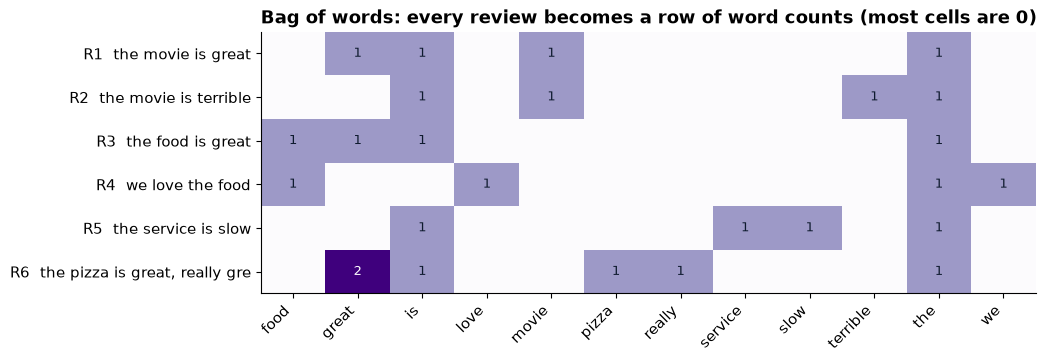

In [23]:
def matrix_heatmap(table, ax, texts, fmt="{:.0f}", cmap="Purples", vmax=None):
    """Colour a documents × words table and write every non-zero value inside its cell."""
    values = table.to_numpy(dtype=float)
    vmax = vmax or values.max()
    ax.imshow(values, cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            if values[i, j] > 0:
                ax.text(j, i, fmt.format(values[i, j]), ha="center", va="center", fontsize=9,
                        color="white" if values[i, j] > 0.6 * vmax else PALETTE["navy"])
    ax.set_xticks(range(values.shape[1]), table.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), [f"{n}  {s[:30]}" for n, s in zip(table.index, texts)])
    ax.grid(False)
    return ax

fig, ax = plt.subplots(figsize=(10, 3.4))
matrix_heatmap(bow_table, ax, reviews)
ax.set_title("Bag of words: every review becomes a row of word counts (most cells are 0)")
plt.show()

### The same thing on the real SMS data

In [24]:
sms_counts = CountVectorizer().fit_transform(sms["text"])
rows, cols = sms_counts.shape
dense_mb = rows * cols * 8 / 1e6
sparse_mb = (sms_counts.data.nbytes + sms_counts.indices.nbytes + sms_counts.indptr.nbytes) / 1e6
print(f"{rows:,} messages × {cols:,} words · on average {sms_counts.nnz / rows:.1f} non-zero cells per row")
print(f"{1 - sms_counts.nnz / (rows * cols):.2%} of the cells are zero")
print(f"memory if we stored every zero: {dense_mb:,.0f} MB · as a sparse matrix: {sparse_mb:.1f} MB")

5,574 messages × 8,713 words · on average 13.3 non-zero cells per row
99.85% of the cells are zero
memory if we stored every zero: 389 MB · as a sparse matrix: 0.9 MB


That is why scikit-learn returns a **sparse matrix**: it stores only the non-zero values and their positions. Once every text is a row of numbers, the table is exactly the **X** you know: add the labels **y** and any classifier can learn one weight per word (section 11), or compare rows to find texts that use the same words (section 7).

### The limit: the bag forgets word order… and negation

In [25]:
def compare_rows(a, b):
    vec = CountVectorizer().fit([a, b])
    table = pd.DataFrame(vec.transform([a, b]).toarray(), index=[a, b], columns=vec.get_feature_names_out())
    display(table)
    print("identical rows?", (table.iloc[0] == table.iloc[1]).all(), "\n")

compare_rows("the movie is good", "the movie is not good")
compare_rows("dog bites man", "man bites dog")
compare_rows("good, not bad", "bad, not good")

,good,is,movie,not,the
the movie is good,1,1,1,0,1
the movie is not good,1,1,1,1,1


identical rows? False 



,bites,dog,man
dog bites man,1,1,1
man bites dog,1,1,1


identical rows? True 



,bad,good,not
"good, not bad",1,1,1
"bad, not good",1,1,1


identical rows? True 



The first pair differs only by one count in the column *not*: the model sees "this text contains *not* somewhere", never "*not* belongs to *good*". The other two pairs give **identical rows** although they mean different things.

### Two classic fixes
- **Fix 1 · n-grams:** also count pairs of neighbouring words (**bigrams**). *"not good"* becomes a column of its own. In scikit-learn: `ngram_range=(1, 2)`.
- **Fix 2 · negation marking:** after *not / no / never / n't*, glue `not_` onto every word until the next punctuation mark.

In [26]:
NEGATORS = {"not", "no", "never"}

def mark_negation(text):
    """'not good movie, but great' → 'not not_good not_movie , but great'."""
    out, negated = [], False
    for token in re.findall(r"[a-z0-9']+|[.,!?;]", text.lower()):
        if token in ".,!?;":
            negated = False
            out.append(token)
            continue
        out.append("not_" + token if negated else token)
        if token in NEGATORS or token.endswith("n't"):
            negated = True
    return " ".join(out)

bigrams = CountVectorizer(ngram_range=(1, 2))
for text in ["not good movie", "not good, but great", "never liked it"]:
    pairs = [g for g in bigrams.fit([text]).get_feature_names_out() if " " in g]
    print(f"{text!r:24} fix 1 adds {pairs}  ·  fix 2: {mark_negation(text)!r}")

compare_rows(mark_negation("good, not bad"), mark_negation("bad, not good"))

'not good movie'         fix 1 adds ['good movie', 'not good']  ·  fix 2: 'not not_good not_movie'
'not good, but great'    fix 1 adds ['but great', 'good but', 'not good']  ·  fix 2: 'not not_good , but great'
'never liked it'         fix 1 adds ['liked it', 'never liked']  ·  fix 2: 'never not_liked not_it'


,bad,good,not,not_bad,not_good
"good , not not_bad",0,1,1,1,0
"bad , not not_good",1,0,1,0,1


identical rows? False 



Now *good* and *not_good* are different columns, and the scope stops at the comma. Neither fix understands language: they are cheap tricks that help counting methods.

### ✏️ Exercise 4 — The price of word pairs (Difficulty ⭐⭐)
Fit `CountVectorizer(ngram_range=(1, 2))` on all `sms["text"]`. How many columns do you get compared with the 8,713 single words? What share of the bigram columns appear in **only one** message?

In [27]:
# TODO: count the columns with bigrams

<details>
<summary>💡 Show solution</summary>

```python
bi = CountVectorizer(ngram_range=(1, 2)).fit_transform(sms["text"])
print("columns with bigrams:", bi.shape[1])                      # ≈ 50,500: almost 6× more
doc_freq = (bi > 0).sum(axis=0).A1                               # in how many messages each column appears
print(f"columns seen in only one message: {(doc_freq == 1).mean():.0%}")
```
Adding pairs multiplies the number of columns by almost 6, and most of the new columns are **rare** (seen once): more memory, more time, and more chances to memorise noise. That is the price of fix 1.
</details>

<a id="sec-6"></a>
# 6. ⚖️ Idea 3: TF-IDF

> 🎞️ **Slides:** [TF: how often in this text](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-tf) · [IDF: how rare across all texts](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-idf) · [TF-IDF = TF × IDF](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-tfidf)

Plain counts have one more problem: the most frequent words are often the least interesting. The slide's new toy corpus of five restaurant reviews:

In [28]:
docs = ["the pizza was great", "the pizza was cold", "the service was slow",
        "the staff was great, great service", "the pasta was great"]
doc_names = [f"D{i}" for i in range(1, 6)]
words_order = ["the", "was", "great", "pizza", "service", "cold", "slow", "staff", "pasta"]

tf = pd.DataFrame(CountVectorizer(vocabulary=words_order).fit_transform(docs).toarray(),
                  index=doc_names, columns=words_order)
tf

,the,was,great,pizza,service,cold,slow,staff,pasta
D1,1,1,1,1,0,0,0,0,0
D2,1,1,0,1,0,1,0,0,0
D3,1,1,0,0,1,0,1,0,0
D4,1,1,2,0,1,0,0,1,0
D5,1,1,1,0,0,0,0,0,1


**Step 1 · TF** (*term frequency*) = how many times the word appears in this document: exactly the bag-of-words count. Look at D4 *"the staff was great, great service"*: by TF, *great* (2) looks most important, and *the* and *was* get the same 1 as *staff*, although *staff* is what makes D4 special.

**Step 2 · IDF** (*inverse document frequency*) is a rarity bonus: $\text{idf} = \ln\frac{N}{\text{df}}$, with $N$ = number of documents and df = in how many documents the word appears (at least once).

In [29]:
N = len(docs)
df = (tf > 0).sum(axis=0)                 # in how many documents?
idf = np.log(N / df)                      # rare word → big bonus; word everywhere → 0
pd.DataFrame({"df (documents)": df, "N / df": (N / df).round(2), "idf = ln(N/df)": idf.round(2)})

,df (documents),N / df,idf = ln(N/df)
the,5,1.00,0.00
was,5,1.00,0.00
great,3,1.67,0.51
pizza,2,2.50,0.92
service,2,2.50,0.92
cold,1,5.00,1.61
slow,1,5.00,1.61
staff,1,5.00,1.61
pasta,1,5.00,1.61


*the* and *was* are in all 5 documents: ln(5/5) = **0**, they are switched off. A word in only one document gets the biggest bonus, ln(5) = **1.61**.

**Step 3 · TF-IDF = TF × IDF.**

In [30]:
tfidf_simple = tf * idf
display(tfidf_simple.round(2))
print("D4, most characteristic words first:")
print(tfidf_simple.loc["D4"].sort_values(ascending=False).round(2).to_dict())

,the,was,great,pizza,service,cold,slow,staff,pasta
D1,0.0,0.0,0.51,0.92,0.00,0.00,0.00,0.00,0.00
D2,0.0,0.0,0.00,0.92,0.00,1.61,0.00,0.00,0.00
D3,0.0,0.0,0.00,0.00,0.92,0.00,1.61,0.00,0.00
D4,0.0,0.0,1.02,0.00,0.92,0.00,0.00,1.61,0.00
D5,0.0,0.0,0.51,0.00,0.00,0.00,0.00,0.00,1.61


D4, most characteristic words first:
{'staff': 1.61, 'great': 1.02, 'service': 0.92, 'the': 0.0, 'was': 0.0, 'pizza': 0.0, 'cold': 0.0, 'slow': 0.0, 'pasta': 0.0}


For D4: *staff* 1 × 1.61 = **1.61** beats *great* 2 × 0.51 = 1.02, and the filler words drop to 0. In D2, *cold* (1.61) beats *pizza* (0.92).

> 🧠 **How it works: TF-IDF**
> - **Idea:** a word is important for a text if it appears **often in this text** (TF) but **rarely in the others** (IDF).
> - **Analogy:** at a party where everyone wears jeans, "jeans" doesn't help you find your friend. "Red hat" does.
> - **Limits:** still a bag (no order, no synonyms); the IDF depends on the corpus it was computed on.

scikit-learn's `TfidfVectorizer` uses a **smoothed** IDF, $\ln\frac{1+N}{1+\text{df}} + 1$ (no word ever gets exactly 0, and the +1 makes the rarity bonus gentler), and then divides each row by its length (L2 norm) so that long and short texts are comparable. The IDF still ranks words the same way, but the final numbers change. Let's reproduce it by hand:

Same numbers as our hand-made version? True


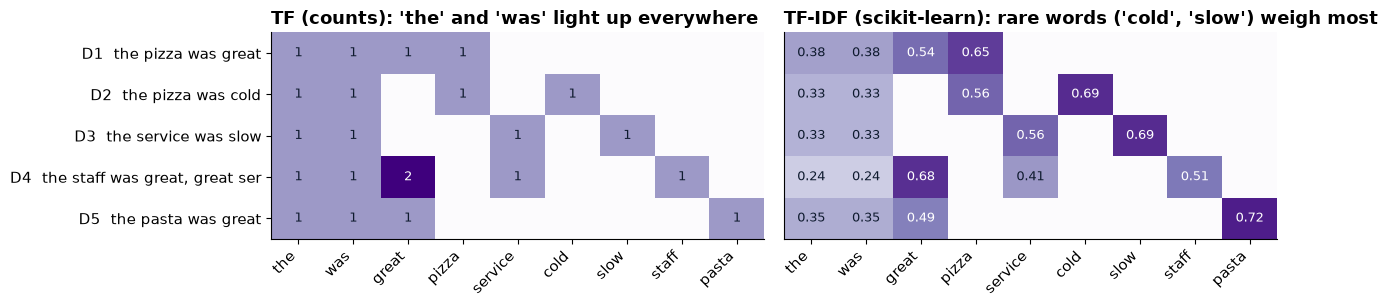

In [31]:
idf_smooth = np.log((1 + N) / (1 + df)) + 1
raw = tf * idf_smooth
tfidf_hand = raw.div(np.sqrt((raw ** 2).sum(axis=1)), axis=0)      # each row to length 1

tfidf_vec = TfidfVectorizer()
tfidf = tfidf_vec.fit_transform(docs)
tfidf_table = pd.DataFrame(tfidf.toarray(), index=doc_names, columns=tfidf_vec.get_feature_names_out())
print("Same numbers as our hand-made version?", np.allclose(tfidf_table[words_order], tfidf_hand))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
matrix_heatmap(tf, axes[0], docs)
axes[0].set_title("TF (counts): 'the' and 'was' light up everywhere")
matrix_heatmap(tfidf_table[words_order], axes[1], docs, fmt="{:.2f}", vmax=0.8)
axes[1].set_title("TF-IDF (scikit-learn): rare words ('cold', 'slow') weigh most")
axes[1].set_yticks([])
fig.tight_layout()
plt.show()

Look at D4 on the right: with the gentler smoothed IDF, *great* (counted twice) now edges out *staff*. Same idea, slightly different trade-off between "frequent here" and "rare elsewhere". *the* and *was* no longer vanish, but they are the weakest words of every row.

### TF-IDF on a real spam message
Fit on all the messages, then read the weights of one spam: which words make it special?

In [32]:
sms_tfidf_vec = TfidfVectorizer()
sms_tfidf = sms_tfidf_vec.fit_transform(sms["text"])
i = 418
row = pd.Series(sms_tfidf[i].toarray().ravel(), index=sms_tfidf_vec.get_feature_names_out())
print(sms.loc[i, "text"])
row[row > 0].sort_values(ascending=False).round(2).to_frame("TF-IDF").T

FREE entry into our £250 weekly competition just text the word WIN to 80086 NOW. 18 T&C www.txttowin.co.uk


,80086,txttowin,competition,250,entry,weekly,into,word,18,co,win,uk,www,our,text,free,just,now,the,to
TF-IDF,0.34,0.34,0.3,0.26,0.26,0.25,0.24,0.23,0.22,0.22,0.21,0.21,0.2,0.18,0.18,0.16,0.15,0.14,0.11,0.09


Rare, specific tokens (*80086*, *txttowin*, *competition*) get the highest weights; common words (*the*, *to*) the lowest. TF-IDF found the "red hats" of this message without any dictionary.

<a id="sec-7"></a>
# 7. 📐 Comparing texts: cosine similarity, and the limit of counting

> 🎞️ **Slides:** [Rows ready for search](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-use) · [Cosine similarity](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-cos) · [Counting doesn't know meaning](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-meaning)

Each review is now a **vector** (an arrow) with one dimension per word. Two reviews that use the same rare words point in **the same direction**.

> 🧠 **How it works: cosine similarity**
> - **Idea:** measure the *angle* between two vectors, not their length. Same direction → 1, nothing in common → 0 (and −1 = opposite, possible with word vectors).
> - **Formula:** $\cos(a, b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}$: the dot product divided by the two lengths.
> - **Analogy:** two people pointing at the same star, one with a short arm and one with a long arm: same direction, same star.

cos(D1, D4) by hand = 0.549 · scikit-learn = 0.549


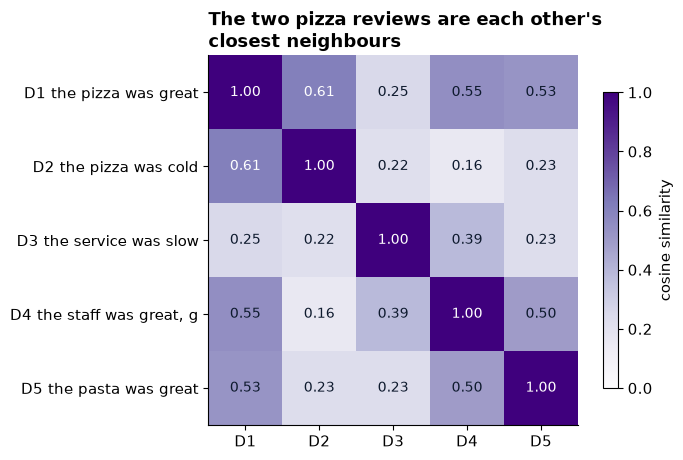

In [33]:
a, b = tfidf[0].toarray().ravel(), tfidf[3].toarray().ravel()           # D1 and D4
by_hand = a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
print(f"cos(D1, D4) by hand = {by_hand:.3f} · scikit-learn = {cosine_similarity(tfidf[0], tfidf[3])[0, 0]:.3f}")

sim = cosine_similarity(tfidf)
fig, ax = plt.subplots(figsize=(6.5, 4.8))
im = ax.imshow(sim, cmap="Purples", vmin=0, vmax=1)
for r in range(N):
    for c in range(N):
        ax.text(c, r, f"{sim[r, c]:.2f}", ha="center", va="center", fontsize=10,
                color="white" if sim[r, c] > 0.6 else PALETTE["navy"])
ax.set_xticks(range(N), doc_names)
ax.set_yticks(range(N), [f"{n} {d[:22]}" for n, d in zip(doc_names, docs)])
ax.grid(False)
ax.set_title("The two pizza reviews are each other's\nclosest neighbours")
fig.colorbar(im, ax=ax, shrink=0.8, label="cosine similarity")
plt.show()

That simple trick is already a tiny **search engine**: turn the query into a TF-IDF row with the *same* vectoriser, then sort the documents by similarity.

In [34]:
def search(query, k=3):
    """Return the k reviews most similar to the query (TF-IDF + cosine)."""
    q = tfidf_vec.transform([query])                 # same vocabulary and IDF as the corpus
    scores = cosine_similarity(q, tfidf).ravel()
    order = scores.argsort()[::-1][:k]
    return pd.DataFrame({"review": [docs[j] for j in order], "similarity": scores[order].round(3)})

display(search("cold pizza"))
display(search("slow service"))

,review,similarity
0,the pizza was cold,0.886
1,the pizza was great,0.406
2,the pasta was great,0.000


,review,similarity
0,the service was slow,0.886
1,"the staff was great, great service",0.257
2,the pasta was great,0.000


### The limit of counting: words are just columns

In [35]:
three = ["a great movie", "an excellent film", "a terrible movie"]
vec3 = CountVectorizer().fit(three)
display(pd.DataFrame(vec3.transform(three).toarray(), index=["A", "B", "C"], columns=vec3.get_feature_names_out()))
s3 = cosine_similarity(vec3.transform(three))
print(f"A · B (same opinion, different words): {s3[0, 1]:.2f}")
print(f"A · C (opposite opinion, shares 'movie'): {s3[0, 2]:.2f}")

,an,excellent,film,great,movie,terrible
A,0,0,0,1,1,0
B,1,1,1,0,0,0
C,0,0,0,0,1,1


A · B (same opinion, different words): 0.00
A · C (opposite opinion, shares 'movie'): 0.50


To bag of words and TF-IDF, *movie* and *film* are as unrelated as *movie* and *pizza*. A spam filter trained on *prize* knows nothing about *reward* unless it saw it in training too. We need numbers where **similar words get similar numbers**.

### ✏️ Exercise 5 — Words the search engine has never seen (Difficulty ⭐)
Search for *"delicious pie"* and for *"the waiter was rude"*. What do you get, and why?

In [36]:
# TODO: try the two queries and explain the scores

<details>
<summary>💡 Show solution</summary>

```python
display(search("delicious pie"))
display(search("the waiter was rude"))
```
*delicious*, *pie*, *waiter* and *rude* are not in the vocabulary: they get no column and are silently ignored. The first query scores 0 everywhere; the second one only matches *the* and *was*, the least informative words, so every review gets about the same score (≈ 0.5) and the ranking means nothing. Bag-of-words knows nothing about **meaning**: *waiter* ≈ *staff* and *pie* ≈ *pizza* are invisible to it. Word vectors (next section) start to fix exactly this.
</details>

<a id="sec-8"></a>
# 8. 🧭 Idea 4: word vectors

> 🎞️ **Slides:** [Similar contexts, similar numbers](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-glove) · [What a word vector looks like](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-vec) · [Words on a map](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-map) · [Cosine similarity](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-cos) · [king − man + woman](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-analogy) · [The limit](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-limits)

*"I drink ____ every morning"*: *coffee* and *tea* both fit, *car* does not. Words used in similar contexts probably mean similar things (*"You shall know a word by the company it keeps"*, J. R. Firth, 1957). **GloVe** (Stanford, 2014) turned this into numbers: it read 6 billion words and gave every word a list of 50 to 300 numbers, so that words with similar neighbours get similar lists.

> 🧠 **How it works: word vectors (embeddings)**
> - **Idea:** every word gets a fixed list of numbers, learned from which words appear around it. Nobody labels anything.
> - **Use:** similar words → vectors pointing the same way (cosine close to 1); directions can carry meaning (*man → woman*).
> - **Limits:** **one vector per word, whatever the sentence**.

> 📦 **Which vectors do we use?** GloVe itself needs a separate download (≥ 70 MB) and an extra library. The MiniLM model we loaded in section 3 contains the same kind of thing: a **table with one fixed vector per token** (30,522 tokens × 384 numbers), learned from huge amounts of text. It is the first layer of the model, before any context is mixed in, so it behaves like GloVe: same idea, different numbers than the slides.

In [37]:
token_table = minilm[0].auto_model.embeddings.word_embeddings.weight.detach().numpy()
unit_table = token_table / np.linalg.norm(token_table, axis=1, keepdims=True)   # length 1 → dot product = cosine
token_id = wordpiece.get_vocab()
id_to_token = {i: t for t, i in token_id.items()}
print("word-vector table:", token_table.shape, "(tokens × numbers)")

def word_vector(word):
    """The fixed vector of a word (it must be a single token of the vocabulary)."""
    if word not in token_id:
        raise KeyError(f"'{word}' is not one token here: {wordpiece.tokenize(word)}")
    return unit_table[token_id[word]]

def cos(w1, w2):
    return float(word_vector(w1) @ word_vector(w2))

def most_similar(vector, k=5, exclude=()):
    """Closest whole words in the vocabulary (no ## pieces, no [special] tokens)."""
    scores = unit_table @ (vector / np.linalg.norm(vector))
    out = []
    for j in np.argsort(-scores):
        w = id_to_token[j]
        if w in exclude or w.startswith(("##", "[")) or not w.isalpha():
            continue
        out.append((w, round(float(scores[j]), 2)))
        if len(out) == k:
            return out

print("king =", np.round(word_vector("king")[:8], 3), "… and 376 more numbers")

word-vector table: (30522, 384) (tokens × numbers)
king = [-0.021  0.017 -0.047 -0.077  0.012  0.007  0.018  0.002] … and 376 more numbers


### What a word vector looks like
Every number becomes one coloured cell. The individual numbers mean nothing to a human, and with 384 of them the patterns are hard to compare by eye; only **comparisons** between whole rows (the cosine, below the picture) tell us which words are close.

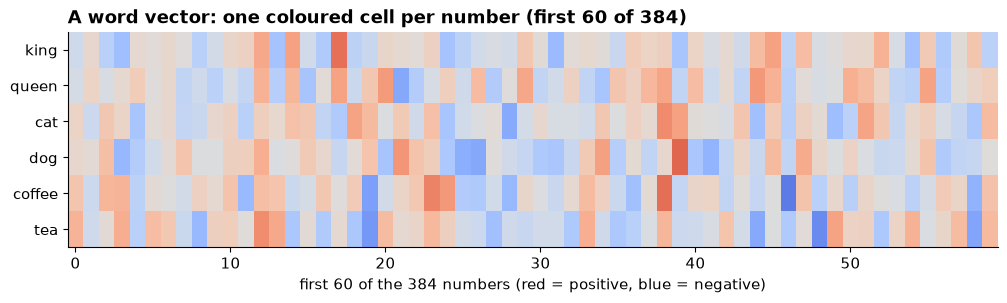

king   · queen  cosine = 0.63
cat    · dog    cosine = 0.42
coffee · tea    cosine = 0.44
king   · coffee cosine = 0.02
cat    · tea    cosine = 0.14


In [38]:
pairs_to_draw = ["king", "queen", "cat", "dog", "coffee", "tea"]
grid = np.array([word_vector(w)[:60] for w in pairs_to_draw])
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.imshow(grid, cmap="coolwarm", vmin=-0.2, vmax=0.2, aspect="auto")
ax.set_yticks(range(len(pairs_to_draw)), pairs_to_draw)
ax.set_xlabel("first 60 of the 384 numbers (red = positive, blue = negative)")
ax.grid(False)
ax.set_title("A word vector: one coloured cell per number (first 60 of 384)")
plt.show()
for a, b in [("king", "queen"), ("cat", "dog"), ("coffee", "tea"), ("king", "coffee"), ("cat", "tea")]:
    v1, v2 = word_vector(a), word_vector(b)
    print(f"{a:6} · {b:6} cosine = {v1 @ v2:.2f}")

### Nearest words and the map

In [39]:
pd.DataFrame({w: [f"{n} {s:.2f}" for n, s in most_similar(word_vector(w), exclude={w})]
              for w in ["cat", "movie", "spain", "great", "prize", "phone"]})

,cat,movie,spain,great,prize,phone
0,cats 0.82,movies 0.82,spanish 0.65,terrific 0.58,prizes 0.72,phones 0.81
1,kitten 0.56,film 0.71,espana 0.59,wonderful 0.58,winner 0.45,telephone 0.70
2,kitty 0.54,films 0.63,spaniards 0.59,excellent 0.57,award 0.45,smartphone 0.60
3,dog 0.42,cinema 0.54,madrid 0.54,fantastic 0.56,winning 0.43,iphone 0.43
4,pets 0.41,filmmakers 0.46,iberian 0.50,tremendous 0.53,contest 0.40,mobile 0.38


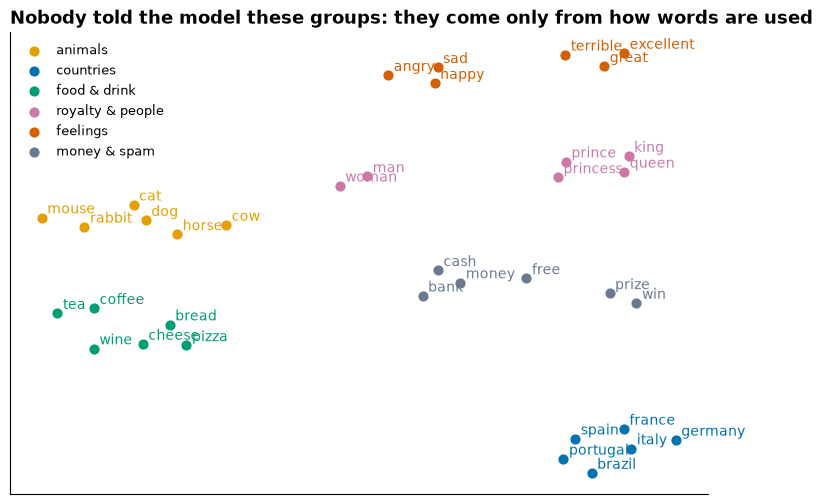

In [40]:
from sklearn.manifold import TSNE

groups = {"animals": ["cat", "dog", "rabbit", "mouse", "horse", "cow"],
          "countries": ["spain", "portugal", "italy", "france", "brazil", "germany"],
          "food & drink": ["coffee", "tea", "pizza", "bread", "cheese", "wine"],
          "royalty & people": ["king", "queen", "prince", "princess", "man", "woman"],
          "feelings": ["happy", "sad", "angry", "great", "excellent", "terrible"],
          "money & spam": ["free", "prize", "cash", "win", "bank", "money"]}
map_words = [w for ws in groups.values() for w in ws]
xy = TSNE(n_components=2, perplexity=5, metric="cosine", init="pca", random_state=SEED).fit_transform(
    np.array([word_vector(w) for w in map_words]))

fig, ax = plt.subplots(figsize=(9, 6))
colours = [PALETTE[c] for c in ("orange", "blue", "green", "purple", "red", "grey")]
k = 0
for (group, ws), colour in zip(groups.items(), colours):
    pts = xy[k:k + len(ws)]
    ax.scatter(pts[:, 0], pts[:, 1], color=colour, s=40, label=group)
    for (x, y), w in zip(pts, ws):
        ax.annotate(w, (x, y), xytext=(4, 3), textcoords="offset points", fontsize=10, color=colour)
    k += len(ws)
ax.set(xticks=[], yticks=[], title="Nobody told the model these groups: they come only from how words are used")
ax.legend(loc="best", fontsize=9)
plt.show()

The map squashes 384 numbers into 2 with **t-SNE** (it keeps neighbours close, but distances between far-away groups are not meaningful). The colours were added by hand; the groups came from the data.

### Cosine similarity between word vectors
Same formula as in section 7. In the bag of words, any two different words have cosine **0**; with word vectors:

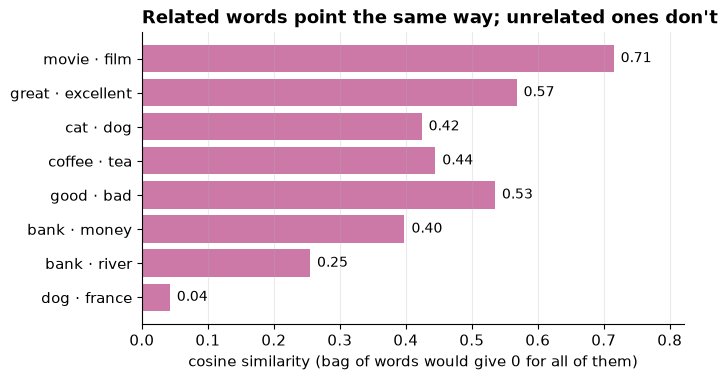

In [41]:
word_pairs = [("movie", "film"), ("great", "excellent"), ("cat", "dog"), ("coffee", "tea"),
              ("good", "bad"), ("bank", "money"), ("bank", "river"), ("dog", "france")]
values = [cos(a, b) for a, b in word_pairs]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh([f"{a} · {b}" for a, b in word_pairs][::-1], values[::-1], color=PALETTE["purple"])
label_bars(ax, values[::-1])
ax.set(xlabel="cosine similarity (bag of words would give 0 for all of them)",
       title="Related words point the same way; unrelated ones don't")
ax.grid(axis="y", visible=False)
plt.show()

### king − man + woman ≈ ?
The arrow from *man* to *woman* is `woman − man`. Add that same arrow to *king* and search the whole vocabulary for the closest word (the three input words excluded, as in every published demo).

In [42]:
result = word_vector("king") - word_vector("man") + word_vector("woman")
print("king − man + woman ≈", most_similar(result, exclude={"king", "man", "woman"}))
result = word_vector("paris") - word_vector("france") + word_vector("italy")
print("paris − france + italy ≈", most_similar(result, exclude={"paris", "france", "italy"}))

king − man + woman ≈ [('queen', 0.5), ('kings', 0.45), ('monarch', 0.41), ('monarchy', 0.37), ('queens', 0.37)]
paris − france + italy ≈ [('italian', 0.48), ('rome', 0.46), ('florence', 0.46), ('milan', 0.41), ('italia', 0.41)]


*queen* comes first among 30,522 tokens. For *paris − france + italy*, *rome* appears near the top (next to *italian*): directions carry meaning, but analogies are a nice illustration, not a guarantee.

### The limit: one vector per word, whatever the sentence

In [43]:
print("closest to 'bank':", most_similar(word_vector("bank"), exclude={"bank"}))
print(f"good · bad = {cos('good', 'bad'):.2f}  (opposites appear in the same sentences, so their vectors are close)")

def average_vector(text):
    """A naive sentence vector: the average of its fixed token vectors."""
    v = np.mean([unit_table[token_id[t]] for t in wordpiece.tokenize(text)], axis=0)
    return v / np.linalg.norm(v)

g, e, t = (average_vector(s) for s in ["great film", "excellent movie", "terrible film"])
print(f"'great film' · 'excellent movie' = {g @ e:.2f}")
print(f"'great film' · 'terrible film'   = {g @ t:.2f}   ← the opposite opinion looks MORE similar!")

closest to 'bank': [('banks', 0.78), ('banking', 0.66), ('bankers', 0.52), ('banker', 0.44), ('banco', 0.43)]
good · bad = 0.53  (opposites appear in the same sentences, so their vectors are close)
'great film' · 'excellent movie' = 0.68
'great film' · 'terrible film'   = 0.73   ← the opposite opinion looks MORE similar!


*bank* has one vector, and its neighbours are all about money: the river meaning is lost. And averaging fixed word vectors makes *"great film"* look closer to *"terrible film"* than to *"excellent movie"*, a real problem for sentiment. **What if a word's vector could change with the words around it?** Keep that question for section 14.

### ✏️ Exercise 6 — Your own analogies (Difficulty ⭐)
Try `most_similar(word_vector(a) - word_vector(b) + word_vector(c), exclude={a, b, c})` for *lisbon − portugal + spain*, *walking − walk + swim* and *bigger − big + small*. Which ones work?

In [44]:
# TODO: three analogies

<details>
<summary>💡 Show solution</summary>

```python
def analogy(a, b, c):
    return most_similar(word_vector(a) - word_vector(b) + word_vector(c), exclude={a, b, c})

for a, b, c in [("lisbon", "portugal", "spain"), ("walking", "walk", "swim"), ("bigger", "big", "small")]:
    print(f"{a} − {b} + {c} ≈ {analogy(a, b, c)}")
```
All three work here (*madrid*, *swimming*, *smaller*): directions such as "capital of", "-ing form" or "-er form" are encoded in the vectors. Many other analogies fail or return a related word that is not the "right" one. If a word is not a single token of the vocabulary, `word_vector` raises an error: pick another word.
</details>

<a id="sec-9"></a>
# 9. 📱 The SMS spam problem

> 🎞️ **Slides:** [Text becomes a table again](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm3-pipeline) · [Spam or ham? You be the filter](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#sms-spam) · [What kind of ML problem?](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm3-mltype)

Bag of words, TF-IDF and word vectors all do the same job: turn any text into a fixed-length row of numbers. Stack the rows, add the label, and we are back to the tables of Lesson 02:

In [45]:
mini = ["Free prize! Call now", "Lunch at home?", "Call me when home"]
mini_vec = TfidfVectorizer().fit(mini)
X_mini = pd.DataFrame(mini_vec.transform(mini).toarray().round(2), index=mini, columns=mini_vec.get_feature_names_out())
X_mini["label (y)"] = ["spam", "ham", "ham"]
X_mini

,at,call,free,home,lunch,me,now,prize,when,label (y)
Free prize! Call now,0.00,0.40,0.53,0.00,0.00,0.00,0.53,0.53,0.00,spam
Lunch at home?,0.62,0.00,0.00,0.47,0.62,0.00,0.00,0.00,0.00,ham
Call me when home,0.00,0.43,0.00,0.43,0.00,0.56,0.00,0.00,0.56,ham


### 🗂️ Meet the data

| | |
|---|---|
| **What** | 5,574 real English SMS messages, each tagged `ham` or `spam` |
| **Source** | Almeida & Hidalgo (2011), *SMS Spam Collection*, UCI Machine Learning Repository ([link](https://archive.ics.uci.edu/dataset/228/sms+spam+collection)), licence CC BY 4.0 |
| **File** | `data/sms_spam/sms_spam.csv` (downloaded automatically the first time, 0.5 MB) |
| **One row =** | one SMS · **Target =** `label` |

More details in the [data dictionary](../../data/DATA_DICTIONARY.md#sms-spam-collection-sms_spam).

### You be the filter
Six real messages, unedited (typos included). Decide for each one: spam or ham? Which clues did you use?

In [46]:
quiz = [418, 1071, 3360, 4357, 3290, 649]
for n, i in enumerate(quiz, start=1):
    print(f"{n}. {sms.loc[i, 'text']}")

1. FREE entry into our £250 weekly competition just text the word WIN to 80086 NOW. 18 T&C www.txttowin.co.uk
2. alright, I'll make sure the car is back tonight
3. Sorry I missed your call let's talk when you have the time. I'm on 07090201529
4. Great. So should i send you my account number.
5. Camera - You are awarded a SiPix Digital Camera! call 09061221066 fromm landline. Delivery within 28 days
6. No prob. I will send to your email.


<details>
<summary>👀 Show the real labels</summary>

1 spam · 2 ham · 3 **spam** (it looks like a friend, but pushes a premium phone number) · 4 **ham** (mentions an "account number", but it is a normal chat) · 5 spam · 6 ham.
</details>

### 💬 Discussion — What kind of ML problem is this?
Supervised or unsupervised? Classification or regression? How many classes?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

**Supervised** (every SMS has a label written by a person) → the label is a category, not a number → **classification** → two categories → **binary classification**. Pitfall: "clustering" is only for data without labels. Bonus: it would become regression if we predicted a number, e.g. a 1–5 star rating. The clues students name (free, win, prize, long numbers, capitals, £) are exactly what a model can learn from word columns.
</details>

**Duplicates.** Many messages repeat (spam campaigns are sent to thousands of people; *"Sorry, I'll call later"* is a phone shortcut). If the same text lands in train **and** test, the model is tested on something it has already memorised: a mild form of the **leakage** we met in Lesson 02. We drop exact duplicates *before* splitting.

In [47]:
n_before = len(sms)
sms = sms.drop_duplicates("text").reset_index(drop=True)
print(f"Removed {n_before - len(sms)} duplicated messages → {len(sms):,} left")
print(f"Spam share: {(sms['label'] == 'spam').mean():.1%}")

Removed 403 duplicated messages → 5,171 left
Spam share: 12.6%


### 🔎 Explore: how do spam and ham differ?

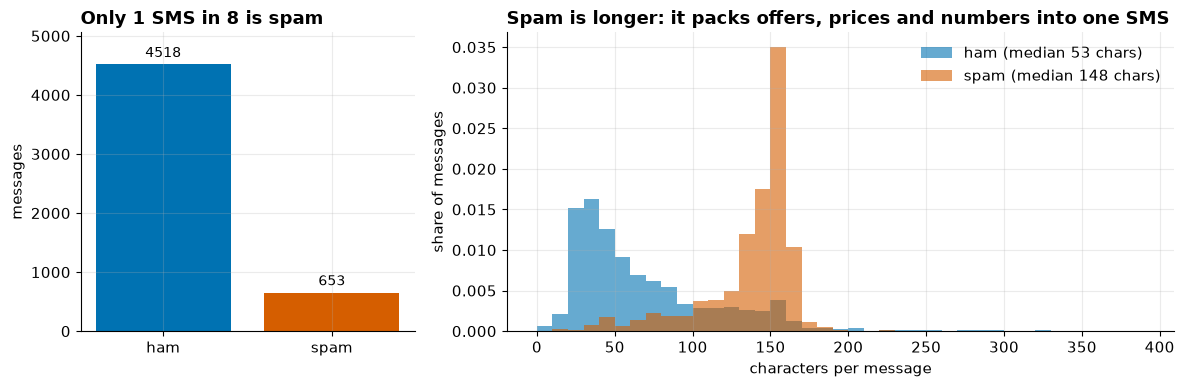

In [48]:
sms["length"] = sms["text"].str.len()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2]})
counts = sms["label"].value_counts()
axes[0].bar(counts.index, counts.values, color=[CLASS_COLORS[c] for c in counts.index])
label_bars(axes[0], counts.values, decimals=0, horizontal=False)
axes[0].set_title("Only 1 SMS in 8 is spam")
axes[0].set_ylabel("messages")
bins = np.arange(0, 400, 10)
for label in ["ham", "spam"]:
    axes[1].hist(sms.loc[sms["label"] == label, "length"], bins=bins, alpha=0.6, density=True,
                 color=CLASS_COLORS[label], label=f"{label} (median {sms.loc[sms['label'] == label, 'length'].median():.0f} chars)")
axes[1].set(xlabel="characters per message", ylabel="share of messages",
            title="Spam is longer: it packs offers, prices and numbers into one SMS")
axes[1].legend()
fig.tight_layout()
plt.show()

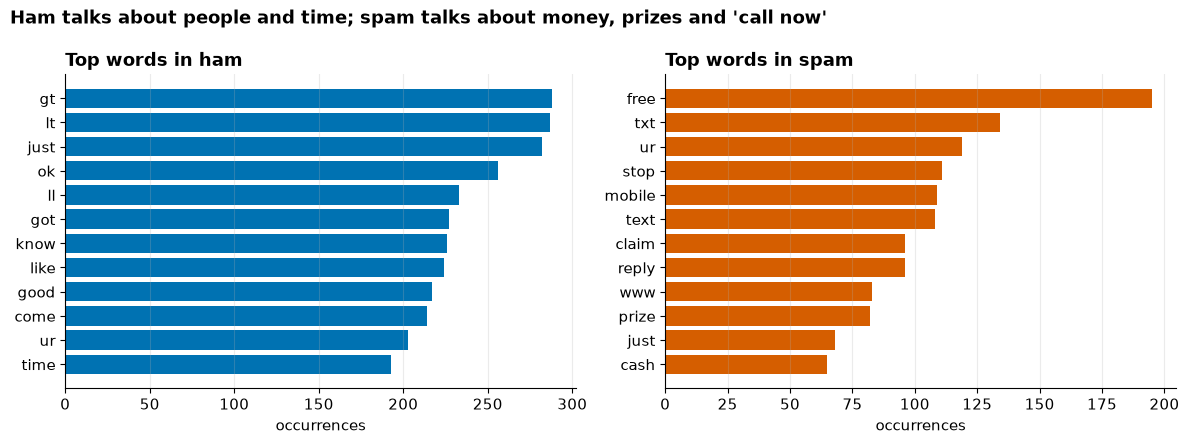

In [49]:
def top_words(texts, n=12):
    """Most frequent words of a list of texts, without English stop words."""
    vec = CountVectorizer(stop_words="english")
    totals = np.asarray(vec.fit_transform(texts).sum(axis=0)).ravel()
    order = totals.argsort()[::-1][:n]
    return pd.Series(totals[order], index=vec.get_feature_names_out()[order])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, label in zip(axes, ["ham", "spam"]):
    words = top_words(sms.loc[sms["label"] == label, "text"])[::-1]
    ax.barh(words.index, words.values, color=CLASS_COLORS[label])
    ax.set_title(f"Top words in {label}")
    ax.set_xlabel("occurrences")
    ax.grid(axis="y", visible=False)
fig.suptitle("Ham talks about people and time; spam talks about money, prizes and 'call now'",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Split first** (stratified, so both parts keep ~12% spam). From now on, everything that learns from data (the vocabulary, the IDF weights, the model) learns **only from the training messages**.

In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    sms["text"], sms["label"], test_size=0.2, stratify=sms["label"], random_state=SEED)
print(f"train: {len(X_train):,} messages · test: {len(X_test):,} messages")

train: 4,136 messages · test: 1,035 messages


<a id="sec-10"></a>
# 10. 📏 Which metric? The accuracy trap

> 🎞️ **Slides:** [The accuracy trap](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm3-acc) · [Precision, recall, F1 and macro-F1](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm3-metrics)

**Spam is the positive class.** Before any real model, a lazy one: it never reads the message and always answers *"ham"*.

In [51]:
def spam_scores(y_true, y_pred):
    """The numbers we compare, with spam as the positive class."""
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision (spam)": precision_score(y_true, y_pred, pos_label="spam", zero_division=0),
            "recall (spam)": recall_score(y_true, y_pred, pos_label="spam"),
            "F1 (spam)": f1_score(y_true, y_pred, pos_label="spam"),
            "macro-F1": f1_score(y_true, y_pred, average="macro")}

results = {}
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
results["Always 'ham' (baseline)"] = spam_scores(y_test, baseline.predict(X_test))
pd.DataFrame(results).T.round(3)

,accuracy,precision (spam),recall (spam),F1 (spam),macro-F1
Always 'ham' (baseline),0.873,0.0,0.0,0.0,0.466


**~87% accuracy and zero spam caught.** When one class is rare, accuracy is dominated by the big class. We need metrics that look at each class:

> 🧠 **How it works: the four numbers** (TP = spam caught, FP = false alarm, FN = spam missed)
> - **Precision** = TP / (TP + FP): when the model says "spam", how often is it right?
> - **Recall** = TP / (TP + FN): of all the real spam, how much did we catch?
> - **F1** = 2·P·R / (P + R): one number, high only if both are high.
> - **Macro-F1**: the F1 of each class, averaged with the same weight, however small the class.

Let's check the slide's toy example (100 SMS: 13 spam, 87 ham; the model catches 10 spam, misses 3 and raises 2 false alarms):

In [52]:
y_true_toy = ["spam"] * 10 + ["spam"] * 3 + ["ham"] * 2 + ["ham"] * 85
y_pred_toy = ["spam"] * 10 + ["ham"] * 3 + ["spam"] * 2 + ["ham"] * 85
pd.Series(spam_scores(y_true_toy, y_pred_toy)).round(2).to_frame("toy model").T

,accuracy,precision (spam),recall (spam),F1 (spam),macro-F1
toy model,0.95,0.83,0.77,0.8,0.89


<a id="sec-11"></a>
# 11. 🤖 Two spam filters: Naive Bayes and Logistic Regression

> 🎞️ **Slides:** [Six classic models for text](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm3-models) · [Now, in practice](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm3-nb01)

A TF-IDF table has thousands of word columns but each SMS uses only a handful: **linear models** (one weight per word) handle that shape easily and fast. We try the two classics. Same recipe as Lesson 02: the `TfidfVectorizer` goes **inside** the `Pipeline`, so it is fitted on the training messages only.

> 🧠 **How it works: Naive Bayes, in plain words**
> - **Idea:** learn, for each word, *how often it shows up in spam* and *how often in ham*. A new message is scored by combining the evidence of its words.
> - **Steps:** (1) count words per class in the training set; (2) turn the counts into probabilities like P(*"prize"* | spam) and P(*"prize"* | ham); (3) for a new SMS, combine the probabilities of all its words with the share of spam overall; (4) pick the class with the higher total.
> - **Why "naive"?** It pretends that words are independent of each other (*"free"* and *"prize"* are of course related). Wrong, but it works surprisingly well and trains in milliseconds.
> - **Analogy:** a detective who keeps a notebook of "clues" (*free, prize, txt, 150p*) and adds up how suspicious each clue is.

**Logistic regression** (Lesson 02's old friend) learns **one weight per word**, adds them up and squashes the total into a probability.

In [53]:
nb_filter = make_pipeline(TfidfVectorizer(), MultinomialNB())
nb_filter.fit(X_train, y_train)
results["TF-IDF + Naive Bayes"] = spam_scores(y_test, nb_filter.predict(X_test))

lr_filter = make_pipeline(TfidfVectorizer(), LogisticRegression(C=10, max_iter=1000))
lr_filter.fit(X_train, y_train)
results["TF-IDF + Logistic Regression"] = spam_scores(y_test, lr_filter.predict(X_test))

pd.DataFrame(results).T.round(3)

,accuracy,precision (spam),recall (spam),F1 (spam),macro-F1
Always 'ham' (baseline),0.873,0.000,0.000,0.000,0.466
TF-IDF + Naive Bayes,0.953,1.000,0.626,0.770,0.872
TF-IDF + Logistic Regression,0.979,0.974,0.855,0.911,0.949


Both filters are far above the baseline. Notice the typical behaviour of **Naive Bayes** with TF-IDF: **perfect precision** (it never flags a normal SMS here) but it **misses more spam**. Logistic Regression finds a better balance. The confusion matrices show the same story in counts:

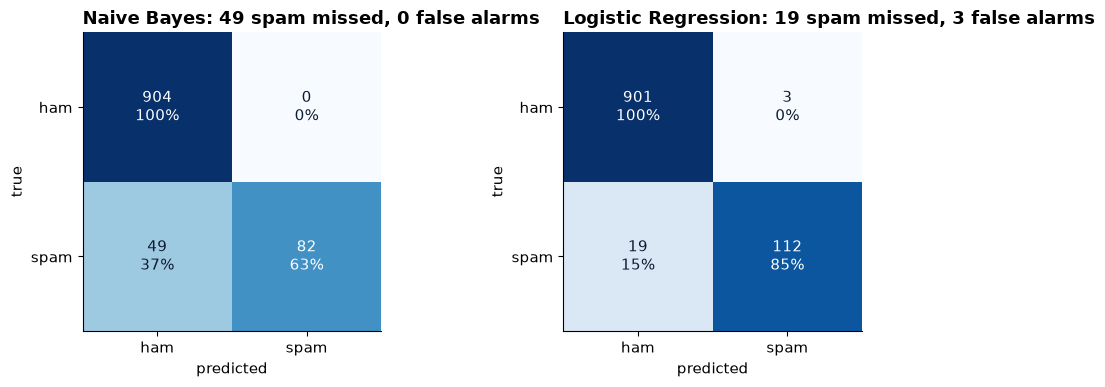

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, [("Naive Bayes", nb_filter), ("Logistic Regression", lr_filter)]):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=["ham", "spam"])
    plot_confusion(cm, ["ham", "spam"], ax=ax, title=f"{name}: {cm[1, 0]} spam missed, {cm[0, 1]} false alarms")
fig.tight_layout()
plt.show()

### ✏️ Exercise 7 — Count or TF-IDF for Naive Bayes? (Difficulty ⭐⭐)
Build `make_pipeline(CountVectorizer(), MultinomialNB())`, train it and add its scores to `results`. Naive Bayes was invented for **counts**: does it do better with counts than with TF-IDF here? (The other classic models of the slides, SVM, KNN, random forest and XGBoost, are compared in the tweet project.)

In [55]:
# TODO: a CountVectorizer + MultinomialNB pipeline, then compare with the table above

<details>
<summary>💡 Show solution</summary>

```python
nb_counts = make_pipeline(CountVectorizer(), MultinomialNB()).fit(X_train, y_train)
results["Counts + Naive Bayes"] = spam_scores(y_test, nb_counts.predict(X_test))
pd.DataFrame(results).T.round(3)
```
With raw counts Naive Bayes **catches much more spam** (recall ≈ 0.89 instead of 0.63) for a small loss of precision (≈ 0.95 instead of 1.00), so its F1 goes up and it even edges out Logistic Regression. Its probabilities come from word counts, which is what the model was designed for. Lesson: the representation and the model go together; always try more than one combination.
</details>

<a id="sec-12"></a>
# 12. 👔 The boss email: which mistake costs more?

> 🎞️ **Slides:** [Spam filter: precision or recall?](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm3-boss)

Two mistakes a spam filter can make:
- **A · false negative** (a spam reaches your inbox): *"WIN a £1,000 prize! Txt CLAIM to 80086"*. You delete it in two seconds.
- **B · false positive** (a real message goes to the spam folder): your boss writes *"Client meeting moved to 9:00 tomorrow. Please confirm."* You miss the meeting.

Our logistic regression did make a few mistakes of type B on the test set. These are real "boss emails":

In [56]:
spam_col = list(lr_filter.classes_).index("spam")
proba = lr_filter.predict_proba(X_test)[:, spam_col]
errors = pd.DataFrame({"text": X_test, "true": y_test, "predicted": lr_filter.predict(X_test), "P(spam)": proba})
false_alarms = errors[(errors["true"] == "ham") & (errors["predicted"] == "spam")]
display(false_alarms[["text", "P(spam)"]].round(3))

boss = "Client meeting moved to 9:00 tomorrow. Please confirm."
print(f"Our invented boss message: P(spam) = {lr_filter.predict_proba([boss])[0, spam_col]:.2f} → it reaches the inbox")

,text,P(spam)
487,Are you free now?can i call now?,0.755
1620,Glad to see your reply.,0.735
4416,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to &...,0.719


Our invented boss message: P(spam) = 0.07 → it reaches the inbox


### 💬 Discussion — Precision or recall for a spam filter?
Which mistake hurts more, A or B? So which metric should a spam filter care about most? Would your answer change for a bank fighting phishing, or for finding angry customers among thousands of tweets?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

For most people **B is worse**: a missed spam costs one second to delete, a hidden message from your boss or your doctor can cost a lot. So a spam filter cares most about **precision** (when it says "spam", it must be right), and providers usually send doubtful messages to a folder you can check instead of deleting them. Flip the situation: finding unhappy customers, or a medical screening, a **missed** case is the costly one, so **recall** matters most. A bank that fights phishing may accept more false alarms because one successful scam is very expensive. When both mistakes matter, report F1. There is no best metric in general: ask what each mistake costs. The model does not decide this; the **threshold** (next cell) does.
</details>

The filter says "spam" when P(spam) ≥ 0.5. Moving that **threshold** trades one mistake for the other:

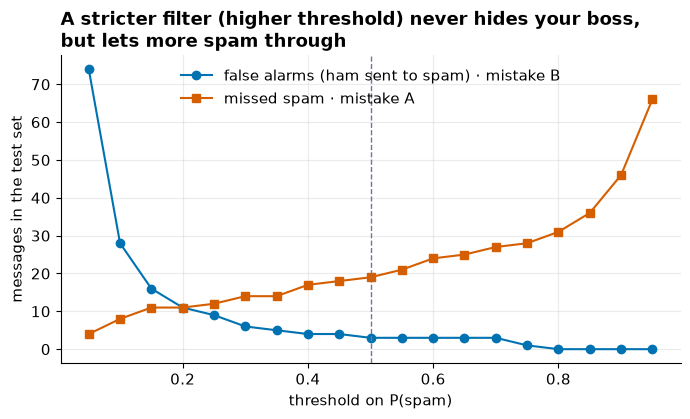

In [57]:
true_spam = (y_test == "spam").to_numpy()
thresholds = np.linspace(0.05, 0.95, 19)
fa = [((proba >= t) & ~true_spam).sum() for t in thresholds]
missed = [((proba < t) & true_spam).sum() for t in thresholds]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thresholds, fa, marker="o", color=CLASS_COLORS["ham"], label="false alarms (ham sent to spam) · mistake B")
ax.plot(thresholds, missed, marker="s", color=CLASS_COLORS["spam"], label="missed spam · mistake A")
ax.axvline(0.5, color=PALETTE["grey"], ls="--", lw=1)
ax.set(xlabel="threshold on P(spam)", ylabel="messages in the test set",
       title="A stricter filter (higher threshold) never hides your boss,\nbut lets more spam through")
ax.legend()
plt.show()

*(In a real project you would choose the threshold on validation data, not on the test set: Lesson 02, threshold tuning.)*

### ✏️ Exercise 8 — A filter that never hides your boss (Difficulty ⭐⭐)
Find the **smallest threshold** that gives **zero false alarms** on the test set. How many spam messages does the filter miss at that threshold, and what are precision and recall?

In [58]:
# TODO: smallest threshold with no false alarms, then precision and recall

<details>
<summary>💡 Show solution</summary>

```python
t_safe = proba[~true_spam].max() + 1e-6          # just above the most "spammy" ham message
flagged = proba >= t_safe
print(f"threshold {t_safe:.2f}: false alarms = {(flagged & ~true_spam).sum()} · missed spam = {(~flagged & true_spam).sum()}")
y_safe = np.where(flagged, "spam", "ham")
print(f"precision = {precision_score(y_test, y_safe, pos_label='spam'):.2f} · recall = {recall_score(y_test, y_safe, pos_label='spam'):.2f}")
```
Around 0.76 the filter has **precision 1.00**, but it misses 28 spam messages instead of 19: recall drops from 0.86 to ≈ 0.79. That is the price of never hiding a real message.
</details>

<a id="sec-13"></a>
# 13. 🔍 What did the model learn, and where does it fail?

A linear model gives **one weight per word**. A positive weight pushes towards *spam*, a negative one towards *ham* (exactly the toy picture of the slide [Rows of counts are ready for machine learning](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm2-use), now with real weights). `top_coefficients` (in `src/text.py`) sorts the vocabulary by weight.

The model learned 7,669 weights, one per word of the training vocabulary.


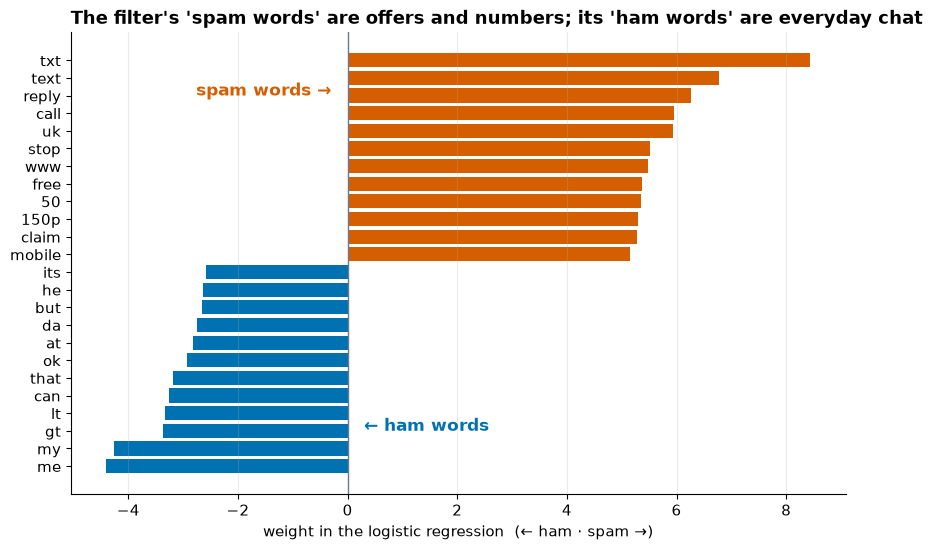

In [59]:
vec, clf = lr_filter.named_steps["tfidfvectorizer"], lr_filter.named_steps["logisticregression"]
print(f"The model learned {clf.coef_.size:,} weights, one per word of the training vocabulary.")
top = top_coefficients(vec, clf, n=12).sort_values("weight")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["word"], top["weight"], color=[CLASS_COLORS[c] for c in top["towards"]])
ax.axvline(0, color=PALETTE["grey"], lw=1)
ax.set(xlabel="weight in the logistic regression  (← ham · spam →)",
       title="The filter's 'spam words' are offers and numbers; its 'ham words' are everyday chat")
ax.grid(axis="y", visible=False)
ax.text(0.3, 2, "← ham words", color=CLASS_COLORS["ham"], ha="left", fontweight="bold", fontsize=12)
ax.text(-0.3, len(top) - 3, "spam words →", color=CLASS_COLORS["spam"], ha="right", fontweight="bold", fontsize=12)
plt.show()

Spam words are things like *txt*, *call*, *free*, *mobile*, *claim*, *uk*, *www*, and short codes. Ham words are *i*, *me*, *my*, *ok*, *ll*, *gt/lt* (from `&lt;#&gt;`, a placeholder this dataset uses in personal messages). Nobody gave the model a list of spam words (unlike a lexicon): it **discovered** them from the labels.

Now the other honest part: the spam it missed.

In [60]:
missed_spam = errors[(errors["true"] == "spam") & (errors["predicted"] == "ham")].sort_values("P(spam)")
print(f"❌ {len(missed_spam)} spam messages the filter missed (lowest P(spam) first):")
missed_spam.head(6)[["text", "P(spam)"]].round(3)

❌ 19 spam messages the filter missed (lowest P(spam) first):


,text,P(spam)
3890,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Da...",0.007
1423,Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 0909972639...,0.024
3743,ringtoneking 84484,0.031
5141,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT....,0.043
4185,Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min,0.057
2303,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about ...,0.066


The missed spam often **looks like a normal message**: no *free*, no *prize*, sometimes a friendly tone or a dating invitation. A bag of words sees the words, not the intention.

<a id="sec-14"></a>
# 14. 🔮 A first look at context

> 🎞️ **Slides:** [One fixed view per word misses context](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm4-context) · [Same word, different vector](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm4-ctxvec) · [From counting words to context](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tm4-plain)

Every method so far looks at each word **alone**: the bag of words loses the order (section 5), a lexicon scores *"not bad at all"* word by word (section 4), and a word-vector table gives *bank* one fixed vector (section 8). A **transformer** lets every word look at the others (*attention*) and mixes their meaning in, so the vector of a word depends on its sentence: a **contextual embedding**. Our MiniLM model is a small transformer (6 layers), so we can watch it happen.

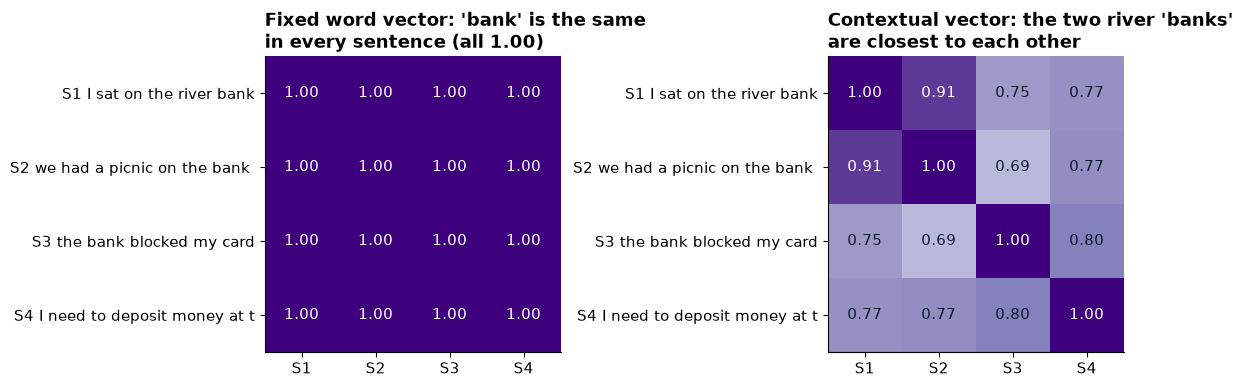

In [61]:
import torch

encoder = minilm[0].auto_model.eval()

def word_in_context(sentence, word):
    """Vector of `word` (a single token) after the 6 transformer layers have read the whole sentence."""
    enc = wordpiece(sentence, return_tensors="pt")
    with torch.no_grad():
        hidden = encoder(**enc).last_hidden_state[0].numpy()
    position = wordpiece.convert_ids_to_tokens(enc["input_ids"][0]).index(word)
    return hidden[position]

bank_sentences = ["I sat on the river bank", "we had a picnic on the bank of the river",
                  "the bank blocked my card", "I need to deposit money at the bank"]
static = np.array([word_vector("bank") for _ in bank_sentences])            # the fixed table: same every time
contextual = np.array([word_in_context(s, "bank") for s in bank_sentences])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, vectors, title in [(axes[0], static, "Fixed word vector: 'bank' is the same\nin every sentence (all 1.00)"),
                           (axes[1], contextual, "Contextual vector: the two river 'banks'\nare closest to each other")]:
    sim_bank = cosine_similarity(vectors)
    ax.imshow(sim_bank, cmap="Purples", vmin=0.5, vmax=1)
    for r in range(4):
        for c in range(4):
            ax.text(c, r, f"{sim_bank[r, c]:.2f}", ha="center", va="center",
                    color="white" if sim_bank[r, c] > 0.85 else PALETTE["navy"])
    ax.set_xticks(range(4), [f"S{i}" for i in range(1, 5)])
    ax.set_yticks(range(4), [f"S{i} {s[:28]}" for i, s in enumerate(bank_sentences, start=1)])
    ax.grid(False)
    ax.set_title(title)
fig.tight_layout()
plt.show()

Same word, same model, different vectors: after reading the sentence, the river *bank* (S1, S2) and the money *bank* (S3, S4) drift apart. The model has no dictionary of meanings; the vector simply moves with the context.

MiniLM was also trained to turn a **whole sentence** into one vector (384 numbers). Compare with the naive average of fixed word vectors from section 8:

In [62]:
phrases = ["great film", "excellent movie", "terrible film"]
sentence_vecs = minilm.encode(phrases, normalize_embeddings=True)
avg_vecs = np.array([average_vector(p) for p in phrases])
pd.DataFrame({"average of fixed word vectors": [avg_vecs[0] @ avg_vecs[1], avg_vecs[0] @ avg_vecs[2]],
              "sentence vector (transformer)": [sentence_vecs[0] @ sentence_vecs[1], sentence_vecs[0] @ sentence_vecs[2]]},
             index=["'great film' · 'excellent movie' (same opinion)", "'great film' · 'terrible film' (opposite)"]).round(2)

,average of fixed word vectors,sentence vector (transformer)
'great film' · 'excellent movie' (same opinion),0.68,0.86
'great film' · 'terrible film' (opposite),0.73,0.65


With context, the same opinion is now clearly closer than the opposite one. Last step: those sentence vectors are just another way to turn an SMS into a row of numbers, so a classic model can learn spam from them (the "feature extraction" way of reusing a pretrained model). Encoding ~5,000 messages takes a few seconds on a CPU:

In [63]:
t0 = time.perf_counter()
E_train = minilm.encode(X_train.tolist(), batch_size=64, normalize_embeddings=True)
E_test = minilm.encode(X_test.tolist(), batch_size=64, normalize_embeddings=True)
print(f"{len(E_train) + len(E_test):,} messages → {E_train.shape[1]} numbers each, in {time.perf_counter() - t0:.0f} s")

emb_filter = LogisticRegression(C=10, max_iter=1000).fit(E_train, y_train)
results["MiniLM sentence vectors + Logistic Regression"] = spam_scores(y_test, emb_filter.predict(E_test))
pd.DataFrame(results).T.round(3)

5,171 messages → 384 numbers each, in 7 s


,accuracy,precision (spam),recall (spam),F1 (spam),macro-F1
Always 'ham' (baseline),0.873,0.000,0.000,0.000,0.466
TF-IDF + Naive Bayes,0.953,1.000,0.626,0.770,0.872
TF-IDF + Logistic Regression,0.979,0.974,0.855,0.911,0.949
MiniLM sentence vectors + Logistic Regression,0.986,0.961,0.931,0.946,0.969


Without ever counting a word, the sentence vectors give a spam filter as good as TF-IDF (or slightly better). On spam, the classic TF-IDF filter is already very strong, fast and explainable: **always compare against the simple model before reaching for a transformer**. The tweet project shows where context pays off more (sarcasm, negation, mixed feelings).

| method | what it sees in *"the movie was not bad at all"* |
|---|---|
| lexicon | a score per word: *bad* is negative → negative ✗ |
| bag of words · TF-IDF | counts, order lost: {all, at, bad, not, …} → often negative ✗ |
| word vectors (GloVe) | one fixed vector per word: the same *bad* everywhere ✗ |
| transformer | each word's vector mixed with its neighbours: *bad* ← *not*, *at all* → positive ✓ |

<a id="sec-15"></a>
# 15. ✍️ Try your own messages

Our `Pipeline` takes **raw text** in and gives a prediction out: tokenising, vocabulary, TF-IDF and the model all travel together. That is what "deploying" a text model looks like.

In [64]:
def check_sms(message, model=lr_filter):
    """Return the spam probability of one message, with a friendly verdict."""
    p = model.predict_proba([message])[0, list(model.classes_).index("spam")]
    verdict = "🚫 SPAM" if p >= 0.5 else "✅ ham"
    return f"{verdict}  (P(spam) = {p:.2f})  ←  {message}"

for message in ["Hey, are we still meeting for lunch tomorrow?",
                "URGENT! You have won a £1000 prize. Call 09061701461 now to claim",
                "Congratulations, you won a free ticket. Reply YES",
                "Can you call me when you are free?"]:
    print(check_sms(message))

✅ ham  (P(spam) = 0.00)  ←  Hey, are we still meeting for lunch tomorrow?
🚫 SPAM  (P(spam) = 1.00)  ←  URGENT! You have won a £1000 prize. Call 09061701461 now to claim
🚫 SPAM  (P(spam) = 0.84)  ←  Congratulations, you won a free ticket. Reply YES
✅ ham  (P(spam) = 0.07)  ←  Can you call me when you are free?


Want to type freely? Run the next cell and write in the box (it needs `ipywidgets`, available locally and in Colab). Try to **fool** the filter: write a spam that looks innocent, or a normal message that looks like spam.

In [65]:
import ipywidgets as widgets

box = widgets.Text(placeholder="Type an SMS and press Enter", continuous_update=False,
                   layout=widgets.Layout(width="90%"))
out = widgets.Output()

def on_enter(change):
    with out:
        print(check_sms(change["new"]))

box.observe(on_enter, names="value")   # runs when you press Enter
display(box, out)

Text(value='', continuous_update=False, layout=Layout(width='90%'), placeholder='Type an SMS and press Enter')

Output()

### ✏️ Exercise 9 — Characters instead of words (Difficulty ⭐⭐⭐)
Spammers write *"FR33 pr1ze"* to dodge word filters, the same problem as unknown words in section 3. Cut the text into small pieces instead: `TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))` (pieces of 2 to 5 characters) with `LogisticRegression(C=10, max_iter=1000)`. Is it better? Compare `check_sms("You are a w1nner! Cl4im your FR33 pr1ze")` with both models.

In [66]:
# TODO: a character n-gram pipeline

<details>
<summary>💡 Show solution</summary>

```python
char_filter = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5)),
                            LogisticRegression(C=10, max_iter=1000)).fit(X_train, y_train)
results["Char 2-5 grams + LogReg"] = spam_scores(y_test, char_filter.predict(X_test))
display(pd.DataFrame(results).T.round(3))
tricky = "You are a w1nner! Cl4im your FR33 pr1ze"
print(check_sms(tricky, model=lr_filter))
print(check_sms(tricky, model=char_filter))
```
Here character n-grams are **better** than words (F1 for spam ≈ 0.94 vs 0.91) and **more robust to spelling tricks**: *pr1ze* still shares pieces like *pr* and *ze* with *prize*, so P(spam) for the tricky message roughly doubles (≈ 0.15 → 0.31). Not enough to cross 0.5: robustness helps, it is not magic. The price: many more columns (slower, more memory). Same trade-off as words vs characters vs sub-words.
</details>

In [67]:
print(f"⏱️ Whole notebook ran in {time.perf_counter() - T_START:.0f} s on this computer.")

⏱️ Whole notebook ran in 14 s on this computer.


<a id="sec-16"></a>
# 16. 📌 Summary

| Idea (slides) | In one line |
|---|---|
| Tokens | Cut text into units; `.split()`, cleaning and stop words are choices for the task |
| Sub-words (BPE, WordPiece) | Merge frequent pairs: common words stay whole, rare words become known pieces, nothing is lost |
| Lexicons | A hand-written score per word, summed; no training, but negation, sarcasm, slang and new tasks break it |
| Vocabulary & bag of words | Every different word is a column; a text = its word counts (order lost, almost all zeros) |
| n-grams, `not_` marking | Cheap fixes so the bag can see *"not good"* |
| TF-IDF | Count × rarity: words frequent here but rare elsewhere weigh more; filler words drop to ~0 |
| Cosine similarity | The angle between two vectors: 1 = same direction, 0 = nothing in common |
| Word vectors | One fixed vector per word, learned from its neighbours: similar words are close, but one vector per word |
| Accuracy trap | With 13% spam, "always ham" gets 87% accuracy: use precision, recall, F1, macro-F1 |
| Boss email | Choose the metric (and the threshold) by the cost of each mistake |
| Naive Bayes / Logistic Regression | Linear models on TF-IDF: fast, strong, and we can read their spam words |
| Context (transformers) | The vector of a word depends on its sentence; compare it with the simple model first |

**✅ Checklist:**
- [ ] I removed duplicates **before** splitting train and test.
- [ ] The vectoriser is **inside** the pipeline (fit on train only).
- [ ] I compared with the "always the majority class" baseline.
- [ ] I chose the positive class (spam) and looked at precision **and** recall.
- [ ] I read the model's top words and some of its mistakes.

<a id="sec-17"></a>
# 17. 📚 Learn more

> 📚 **Learn more**
> - scikit-learn User Guide: [Text feature extraction (bag of words, TF-IDF)](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction) · [Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html) · [Working with text data (tutorial)](https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html)
> - Hugging Face LLM course: [Tokenizers](https://huggingface.co/learn/llm-course/chapter2/4) and [Byte-Pair Encoding tokenization](https://huggingface.co/learn/llm-course/chapter6/5).
> - Jurafsky & Martin, *Speech and Language Processing* (3rd ed. draft, free online): [chapters on Naive Bayes and on vector semantics (TF-IDF, cosine, word vectors)](https://web.stanford.edu/~jurafsky/slp3/).
> - Jay Alammar, [The Illustrated Word2vec](https://jalammar.github.io/illustrated-word2vec/) and [The Illustrated Transformer](https://jalammar.github.io/illustrated-transformer/).
> - Pennington, Socher & Manning (2014). [GloVe: Global Vectors for Word Representation](https://nlp.stanford.edu/projects/glove/). · Sennrich, Haddow & Birch (2016). *Neural Machine Translation of Rare Words with Subword Units* (BPE).
> - Almeida, Hidalgo & Yamakami (2011). *Contributions to the study of SMS spam filtering: new collection and results*. ACM DocEng. (The paper behind our dataset.)
>
> 🤖 **Link to modern AI:** large language models start exactly like this notebook: sub-word tokens → token ids → a table of vectors. The difference is the stack of attention layers on top. The tweet project uses these models on a harder problem.

---
<div align="center">

⬅️ [Previous: Lesson 02 · Machine Learning fundamentals](https://github.com/the-ai-learning-hub/02-machine-learning-fundamentals) &nbsp;·&nbsp; 🏠 [Lesson 03](../../README.md) &nbsp;·&nbsp; [Next: 02 · Tweet sentiment project](../02_project_tweets/02.0_Tweets_EDA.ipynb) ➡️

**The AI Learning Hub** · Lesson 03 — Applied AI: unstructured data<br>
MIT License

</div>